# This notebook contains large part of the financing and exploration graphs we tried creating, the cleaned version has all of the useful ones 

# Start Pyspark Session 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
import numpy as np
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, when, lag, mean, stddev, avg, count
from pyspark.sql.window import Window
import pyspark.sql.functions as F
from pyspark.sql import SparkSession

# Create SparkSession
spark = SparkSession.builder \
    .appName("ParquetLoader") \
    .config("spark.some.config.option", "some-value") \
    .getOrCreate()

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
25/12/17 12:47:27 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


# Parquet File Loading 

In [2]:
basetable = spark.read.parquet('../Cleaned_data/biweekly_basetable_w_sentiment_5.parquet')

In [3]:
basetable.show()

25/12/17 12:47:30 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+--------+---------------+--------------+------+--------------------+---------+------------+----------+-----------+------------+-----------+----------+------------------+--------------------+-----------------------+--------------------+--------------------+--------------------+--------------------+--------------------+------------+------------------+----------------+------------------+------------------+--------------------+---------+--------------------+--------------------+-------+---------+---------------------+------------------------+-----------------------+--------+--------------------+-------------------------+-------------+--------------------+---------------------+---------------------+----------------------+--------------+------------------------+-------------------------+------------------------------+---------------------------+----------------------------------+---------------------------------+--------------------+-------------------+------------------+---------+---------

# Check How many financing events there are in our dataset

In [4]:
count = basetable.filter(col("current_financing_announcement") == 1).count()
print(f"Financing announcements (1): {count:,}")

Financing announcements (1): 33


In [5]:
basetable.columns

['industry',
 'biweekly_period',
 'biweekly_index',
 'ticker',
 'longname',
 'benchmark',
 'period_start',
 'period_end',
 'period_open',
 'period_close',
 'period_high',
 'period_low',
 'avg_close',
 'period_return',
 'benchmark_period_return',
 'beta',
 'price_volatility',
 'return_volatility',
 'avg_intraday_range',
 'max_intraday_range',
 'total_volume',
 'avg_daily_volume',
 'max_daily_volume',
 'volume_volatility',
 'avg_volume_up_days',
 'avg_volume_down_days',
 'gap_count',
 'avg_gap_size',
 'max_gap',
 'up_days',
 'down_days',
 'financing_next_period',
 'has_property_acquisition',
 'has_exploration_results',
 'maturity',
 'avg_prChg',
 'price_deviation_from_year',
 'has_financing',
 'prev_period_return',
 'prev_price_volatility',
 'prev_avg_daily_volume',
 'prev_volume_volatility',
 'prev_gap_count',
 'prev_exploration_results',
 'prev_property_acquisition',
 'current_financing_announcement',
 'prev_financing_announcement',
 'second_prev_financing_announcement',
 'third_prev_f

## Find all financing announcements 

In [6]:
df = basetable

In [7]:
# Get all financing announcements
financing_events = df.filter(col("current_financing_announcement") == 1)

# Get the count as a number
financing_count = financing_events.count()

print(f"✓ Found {financing_count:,} financing announcement events")

# Show some examples
print("\nFirst 10 financing events:")
financing_events.select(
    "ticker", 
    "biweekly_index", 
    "period_start", 
    "period_end",
    "has_exploration_results"
).show(10)

# Count financing events per ticker
print("\nFinancing events per ticker:")
ticker_counts = financing_events.groupBy("ticker") \
    .agg(F.count("*").alias("financing_count")) \
    .orderBy(F.col("financing_count").desc())

ticker_counts.show(10)
print(f"  - Unique tickers with financing: {ticker_counts.count()}")

✓ Found 33 financing announcement events

First 10 financing events:
+-------+--------------+------------+----------+-----------------------+
| ticker|biweekly_index|period_start|period_end|has_exploration_results|
+-------+--------------+------------+----------+-----------------------+
|  FNM.V|            15|  2024-08-12|2024-08-23|                      0|
|  FNM.V|            23|  2024-12-02|2024-12-13|                      0|
|  FNM.V|            36|  2025-06-02|2025-06-13|                      0|
|  FNM.V|            42|  2025-08-25|2025-08-29|                      0|
|FURY.TO|            19|  2024-10-07|2024-10-18|                      0|
|FURY.TO|            36|  2025-06-02|2025-06-13|                      0|
| FOM.TO|            31|  2025-03-24|2025-04-04|                      0|
| ELO.TO|             1|  2024-01-29|2024-02-09|                      0|
| ELO.TO|             6|  2024-04-08|2024-04-19|                      0|
| ELO.TO|            31|  2025-03-24|2025-04-04|       

## Check for exploration results before each financing 

In [8]:
# Step 3: Check for Exploration Results Before Each Financing
print("\n" + "="*70)
print("STEP 3: CHECKING FOR EXPLORATION RESULTS BEFORE FINANCING")
print("="*70)

# For each financing event, check if there were exploration results in previous periods
# We need to look at each ticker's history

# Create a window to look at previous periods for each ticker
from pyspark.sql.window import Window

window_spec = Window.partitionBy("ticker").orderBy("biweekly_index")


# prev_exploration_in_window = if there was exploration in 4 previous periods
# has_exploration_results is 1 if there are exploration results in the current period
df_with_exploration_check = df.withColumn(
    "prev_exploration_in_window",
    F.max(col("has_exploration_results")).over(  # Use col() here
        window_spec.rowsBetween(-4, -1)  # Look at 4 previous periods
    )
)

# Now filter for financing events and check if they had exploration results before
financing_with_analysis = df_with_exploration_check.filter(
    col("current_financing_announcement") == 1
)

print("✓ Analysis setup complete")
print("\nSample of financing events with exploration check:")
financing_with_analysis.select(
    "ticker",
    "biweekly_index",
    "current_financing_announcement",
    "has_exploration_results",
    "prev_exploration_in_window"
).show(10, truncate=False)


STEP 3: CHECKING FOR EXPLORATION RESULTS BEFORE FINANCING
✓ Analysis setup complete

Sample of financing events with exploration check:
+------+--------------+------------------------------+-----------------------+--------------------------+
|ticker|biweekly_index|current_financing_announcement|has_exploration_results|prev_exploration_in_window|
+------+--------------+------------------------------+-----------------------+--------------------------+
|AYA.TO|33            |1                             |0                      |1                         |
|AYA.TO|36            |1                             |1                      |1                         |
|CGC.V |22            |1                             |0                      |1                         |
|CGC.V |23            |1                             |1                      |1                         |
|CGC.V |25            |1                             |0                      |1                         |
|CGC.V |30     

# Calculate counts of financing events with exploration results before them

In [9]:
# Count financing events with exploration results before them
with_exploration = financing_with_analysis.filter(
    col("prev_exploration_in_window") == 1
).count()

# Count financing events without exploration results before them
without_exploration = financing_with_analysis.filter(
    (col("prev_exploration_in_window") == 0) | (col("prev_exploration_in_window").isNull())
).count()

total_financing = financing_with_analysis.count()

print(f"✓ Counts calculated:")
print(f"\nTOTAL FINANCING EVENTS: {total_financing:,}")
print("-" * 40)
print(f"Financing WITH exploration results before (within 4 periods): {with_exploration:,}")
print(f"  Percentage: {(with_exploration/total_financing*100):.1f}%")
print()
print(f"Financing WITHOUT exploration results before (within 4 periods): {without_exploration:,}")
print(f"  Percentage: {(without_exploration/total_financing*100):.1f}%")

# Double-check the math
print(f"\n✓ Verification: {with_exploration} + {without_exploration} = {with_exploration + without_exploration}")
print(f"  Should equal total: {total_financing}")
print(f"  Match: {with_exploration + without_exploration == total_financing}")

✓ Counts calculated:

TOTAL FINANCING EVENTS: 33
----------------------------------------
Financing WITH exploration results before (within 4 periods): 22
  Percentage: 66.7%

Financing WITHOUT exploration results before (within 4 periods): 11
  Percentage: 33.3%

✓ Verification: 22 + 11 = 33
  Should equal total: 33
  Match: True


# Calculate time between exploration and financing

In [10]:
# First, let's find the most recent exploration before each financing
# We need to create a more detailed analysis

# Collect all events where exploration happened
exploration_events = df.filter(col("has_exploration_results") == 1) \
    .select("ticker", "biweekly_index", "period_start") \
    .withColumnRenamed("biweekly_index", "exploration_index") \
    .withColumnRenamed("period_start", "exploration_date")

# Collect all financing events
financing_events = df.filter(col("current_financing_announcement") == 1) \
    .select("ticker", "biweekly_index", "period_start") \
    .withColumnRenamed("biweekly_index", "financing_index") \
    .withColumnRenamed("period_start", "financing_date")

print(f"✓ Found {exploration_events.count():,} exploration events")
print(f"✓ Found {financing_events.count():,} financing events")

# Join to find exploration events that occurred before financing
# We'll do this per ticker
exploration_before_financing = financing_events.alias("f") \
    .join(exploration_events.alias("e"),
          (col("f.ticker") == col("e.ticker")) & 
          (col("e.exploration_index") < col("f.financing_index"))
    )

print(f"\n✓ After join (exploration before financing): {exploration_before_financing.count():,} pairs")

✓ Found 79 exploration events
✓ Found 33 financing events

✓ After join (exploration before financing): 113 pairs


# Find closest exploration result before financing 

In [11]:

# Calculate time difference for each pair
pairs_with_diff = exploration_before_financing.withColumn(
    "periods_between",
    col("f.financing_index") - col("e.exploration_index")
)

print("\nSample of exploration-financing pairs:")
pairs_with_diff.select(
    "f.ticker",
    "e.exploration_index",
    "f.financing_index",
    "periods_between"
).show(10)

# For each financing event, find the closest exploration
from pyspark.sql.window import Window

window_spec_closest = Window.partitionBy("f.ticker", "f.financing_index") \
    .orderBy("periods_between")

closest_exploration = pairs_with_diff.withColumn(
    "row_num",
    F.row_number().over(window_spec_closest)
).filter(col("row_num") == 1).drop("row_num")

print(f"\n✓ Found {closest_exploration.count():,} closest exploration-financing pairs")
print("\nSample of closest explorations:")
closest_exploration.select(
    "f.ticker",
    "e.exploration_index",
    "f.financing_index",
    "periods_between"
).show(10)


Sample of exploration-financing pairs:
+-------+-----------------+---------------+---------------+
| ticker|exploration_index|financing_index|periods_between|
+-------+-----------------+---------------+---------------+
|  FNM.V|               10|             15|              5|
|  FNM.V|               10|             23|             13|
|  FNM.V|               35|             36|              1|
|  FNM.V|               34|             36|              2|
|  FNM.V|               10|             36|             26|
|  FNM.V|               41|             42|              1|
|  FNM.V|               35|             42|              7|
|  FNM.V|               34|             42|              8|
|  FNM.V|               10|             42|             32|
|FURY.TO|               18|             19|              1|
+-------+-----------------+---------------+---------------+
only showing top 10 rows

✓ Found 33 closest exploration-financing pairs

Sample of closest explorations:
+------+------

# Analyze time gaps 

In [12]:
# Calculate statistics on the time gaps
if closest_exploration.count() > 0:
    gap_stats = closest_exploration.agg(
        F.count("*").alias("total_pairs"),
        F.min("periods_between").alias("min_periods"),
        F.max("periods_between").alias("max_periods"),
        F.avg("periods_between").alias("avg_periods"),
        F.expr("percentile_approx(periods_between, 0.5)").alias("median_periods"),
        F.expr("percentile_approx(periods_between, 0.25)").alias("q1_periods"),
        F.expr("percentile_approx(periods_between, 0.75)").alias("q3_periods")
    )
    
    print("✓ Time gap statistics (in biweekly periods):")
    gap_stats.show(vertical=True)
    
    # Convert to pandas for easier display
    gap_stats_pd = gap_stats.toPandas()
    print("\nTime Between Exploration and Financing:")
    print("-" * 50)
    for col_name in gap_stats_pd.columns:
        value = gap_stats_pd[col_name].iloc[0]
        if col_name != "total_pairs":
            print(f"{col_name.replace('_', ' ').title()}: {value:.1f} periods")
        else:
            print(f"{col_name.replace('_', ' ').title()}: {int(value):,}")
    
    # Show distribution
    print("\n✓ Distribution of time gaps:")
    distribution = closest_exploration.groupBy("periods_between") \
        .agg(F.count("*").alias("count")) \
        .orderBy("periods_between")
    
    print("\nTop 20 most common time gaps:")
    distribution.show(20)
    
    # Calculate how many are within 4 periods
    within_4_periods = closest_exploration.filter(col("periods_between") <= 4).count()
    total_pairs = closest_exploration.count()
    
    print(f"\n✓ Exploration events within 4 periods of financing:")
    print(f"  Count: {within_4_periods:,}")
    print(f"  Percentage: {(within_4_periods/total_pairs*100):.1f}%")
else:
    print("⚠ No exploration-financing pairs found!")

✓ Time gap statistics (in biweekly periods):
-RECORD 0---------------------------
 total_pairs    | 33                
 min_periods    | 1                 
 max_periods    | 19                
 avg_periods    | 4.393939393939394 
 median_periods | 2                 
 q1_periods     | 1                 
 q3_periods     | 6                 


Time Between Exploration and Financing:
--------------------------------------------------
Total Pairs: 33
Min Periods: 1.0 periods
Max Periods: 19.0 periods
Avg Periods: 4.4 periods
Median Periods: 2.0 periods
Q1 Periods: 1.0 periods
Q3 Periods: 6.0 periods

✓ Distribution of time gaps:

Top 20 most common time gaps:
+---------------+-----+
|periods_between|count|
+---------------+-----+
|              1|   16|
|              2|    4|
|              3|    1|
|              4|    1|
|              5|    2|
|              6|    1|
|              7|    1|
|              9|    1|
|             10|    2|
|             12|    1|
|             13|    1|
|

# Create Visualizations 


Creating visualization 1: Financing with/without exploration...


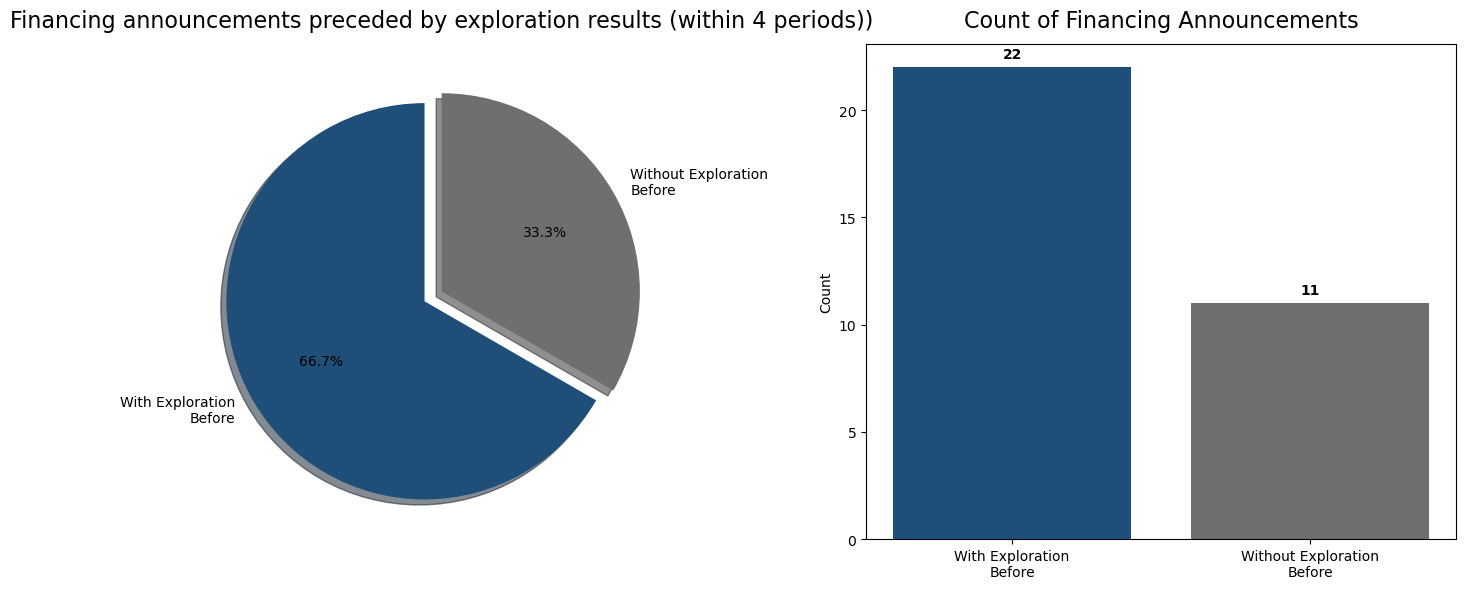


Creating visualization 2: Time gaps histogram...


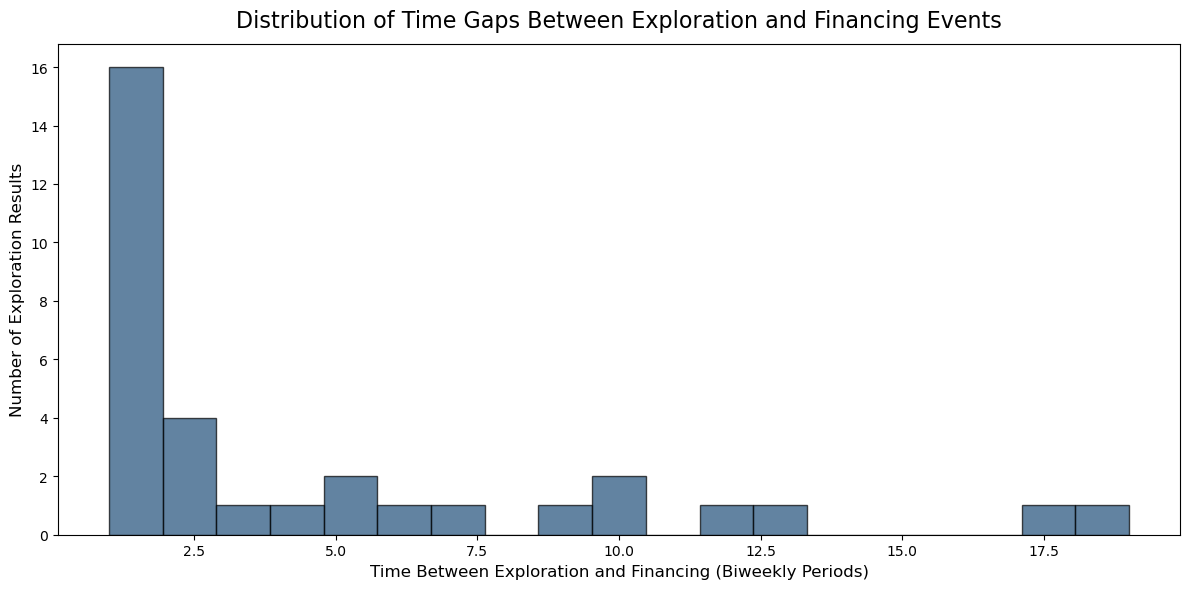

In [16]:
# Convert data to pandas for visualization
import matplotlib.pyplot as plt
import numpy as np

# 1. Pie chart for financing with/without exploration
print("\nCreating visualization 1: Financing with/without exploration...")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Pie chart
labels = ['With Exploration\nBefore', 'Without Exploration\nBefore']
sizes = [with_exploration, without_exploration]
colors = ['#1f4e79', '#6f6f6f']
explode = (0.1, 0)

axes[0].pie(sizes, explode=explode, labels=labels, colors=colors,
           autopct='%1.1f%%', shadow=True, startangle=90)
axes[0].set_title('Financing announcements preceded by exploration results (within 4 periods))', 
                  pad=12, fontsize = 16)

# Bar chart
axes[1].bar(labels, sizes, color=colors)
axes[1].set_title('Count of Financing Announcements', pad=12, fontsize = 16)
axes[1].set_ylabel('Count')
for i, v in enumerate(sizes):
    # FIXED: Use np.max() to avoid PySpark conflict
    axes[1].text(i, v + np.max(sizes)*0.02, f'{v:,}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

# 2. Histogram of time gaps
print("\nCreating visualization 2: Time gaps histogram...")

if closest_exploration.count() > 0:
    # Convert time gaps to pandas for histogram
    time_gaps_pd = closest_exploration.select("periods_between").toPandas()
    
    fig, ax = plt.subplots(figsize=(12, 6))
    
    # Create histogram - FIXED: Use np.minimum instead of min()
    # Calculate bins separately to be clear
    max_gap = int(time_gaps_pd['periods_between'].max())
    bins_value = np.minimum(30, max_gap)  # Use np.minimum here!
    
    n, bins, patches = ax.hist(time_gaps_pd['periods_between'], 
                              bins=bins_value,
                              color=colors[0],
                              edgecolor='black', alpha=0.7)
    
    ax.set_xlabel('Time Between Exploration and Financing (Biweekly Periods)', fontsize=12)
    ax.set_ylabel('Number of Exploration Results', fontsize=12)
    ax.set_title('Distribution of Time Gaps Between Exploration and Financing Events', 
                 pad=12, fontsize = 16)
    
    # Add statistics text
    '''stats_text = f"""Statistics:
    Min: {time_gaps_pd['periods_between'].min():.0f} periods
    Max: {time_gaps_pd['periods_between'].max():.0f} periods
    Mean: {time_gaps_pd['periods_between'].mean():.1f} periods
    Median: {time_gaps_pd['periods_between'].median():.1f} periods
    Total pairs: {len(time_gaps_pd):,}"""
    
    ax.text(0.98, 0.98, stats_text, transform=ax.transAxes,
           fontsize=10, verticalalignment='top', horizontalalignment='right',
           bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    '''
    plt.tight_layout()
    plt.show()
else:
    print("⚠ Skipping time gap histogram - no data available")


Creating visualization 1: Financing with/without exploration...


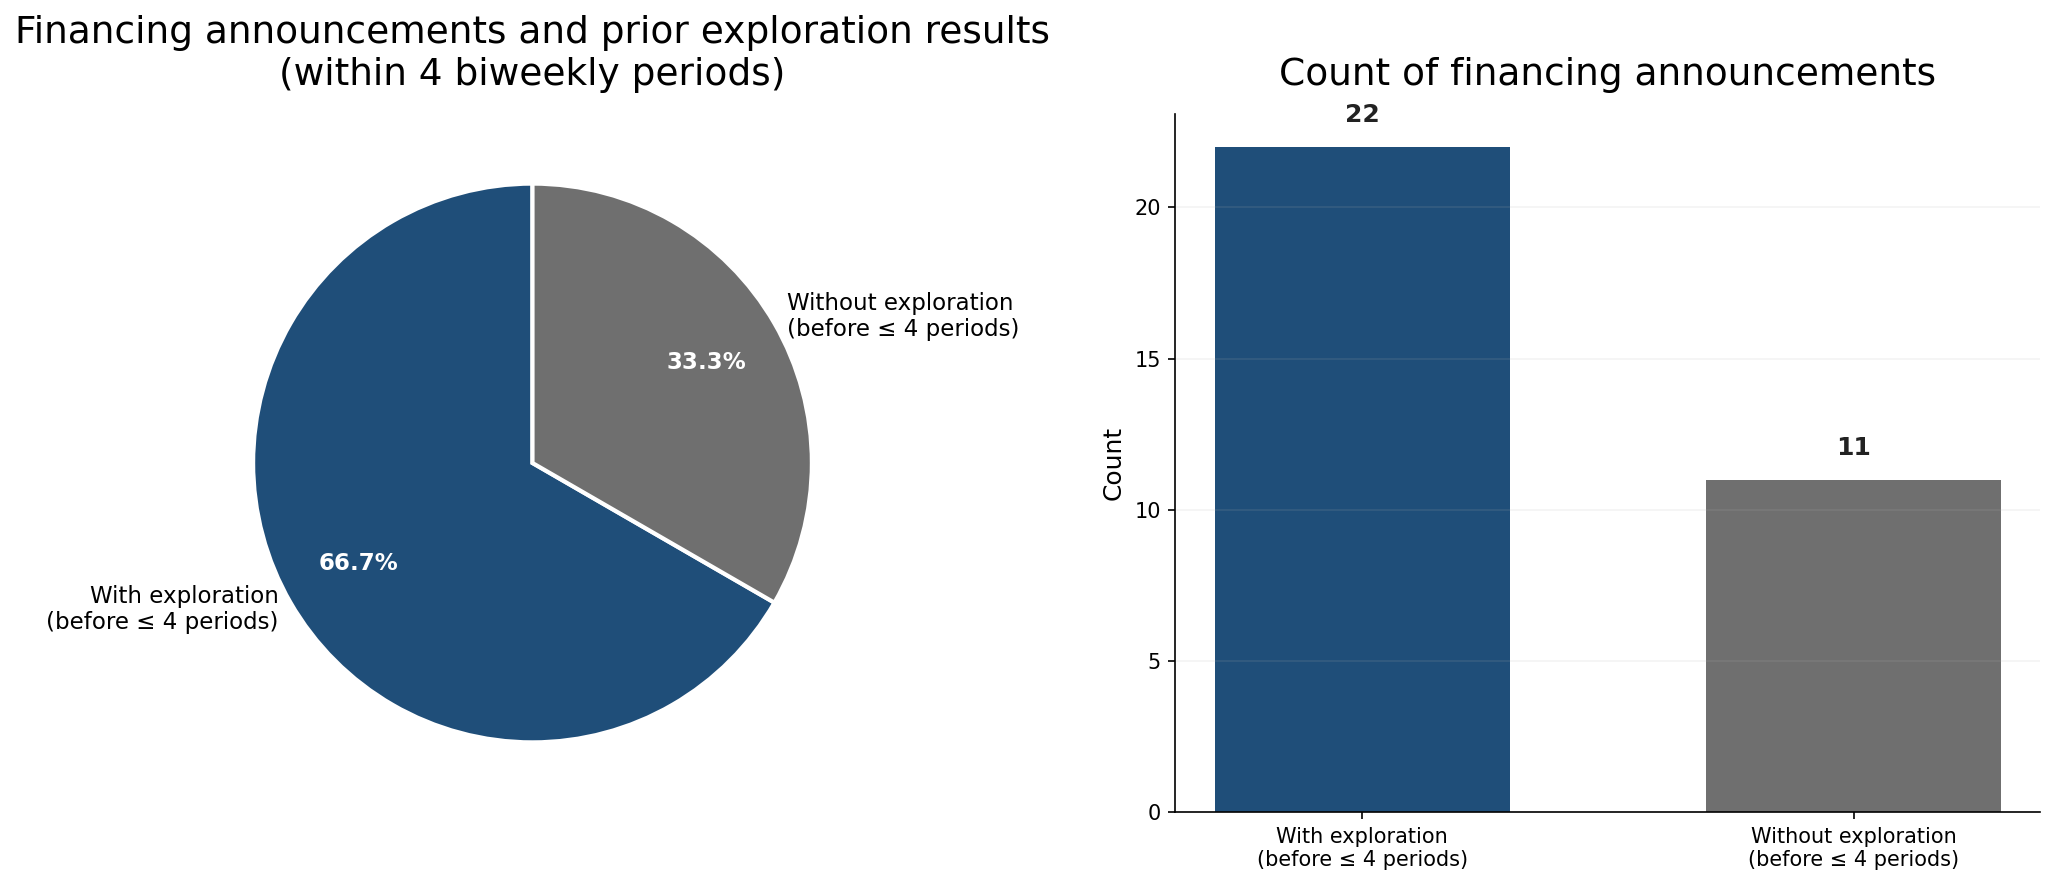


Creating visualization 2: Time gaps histogram...


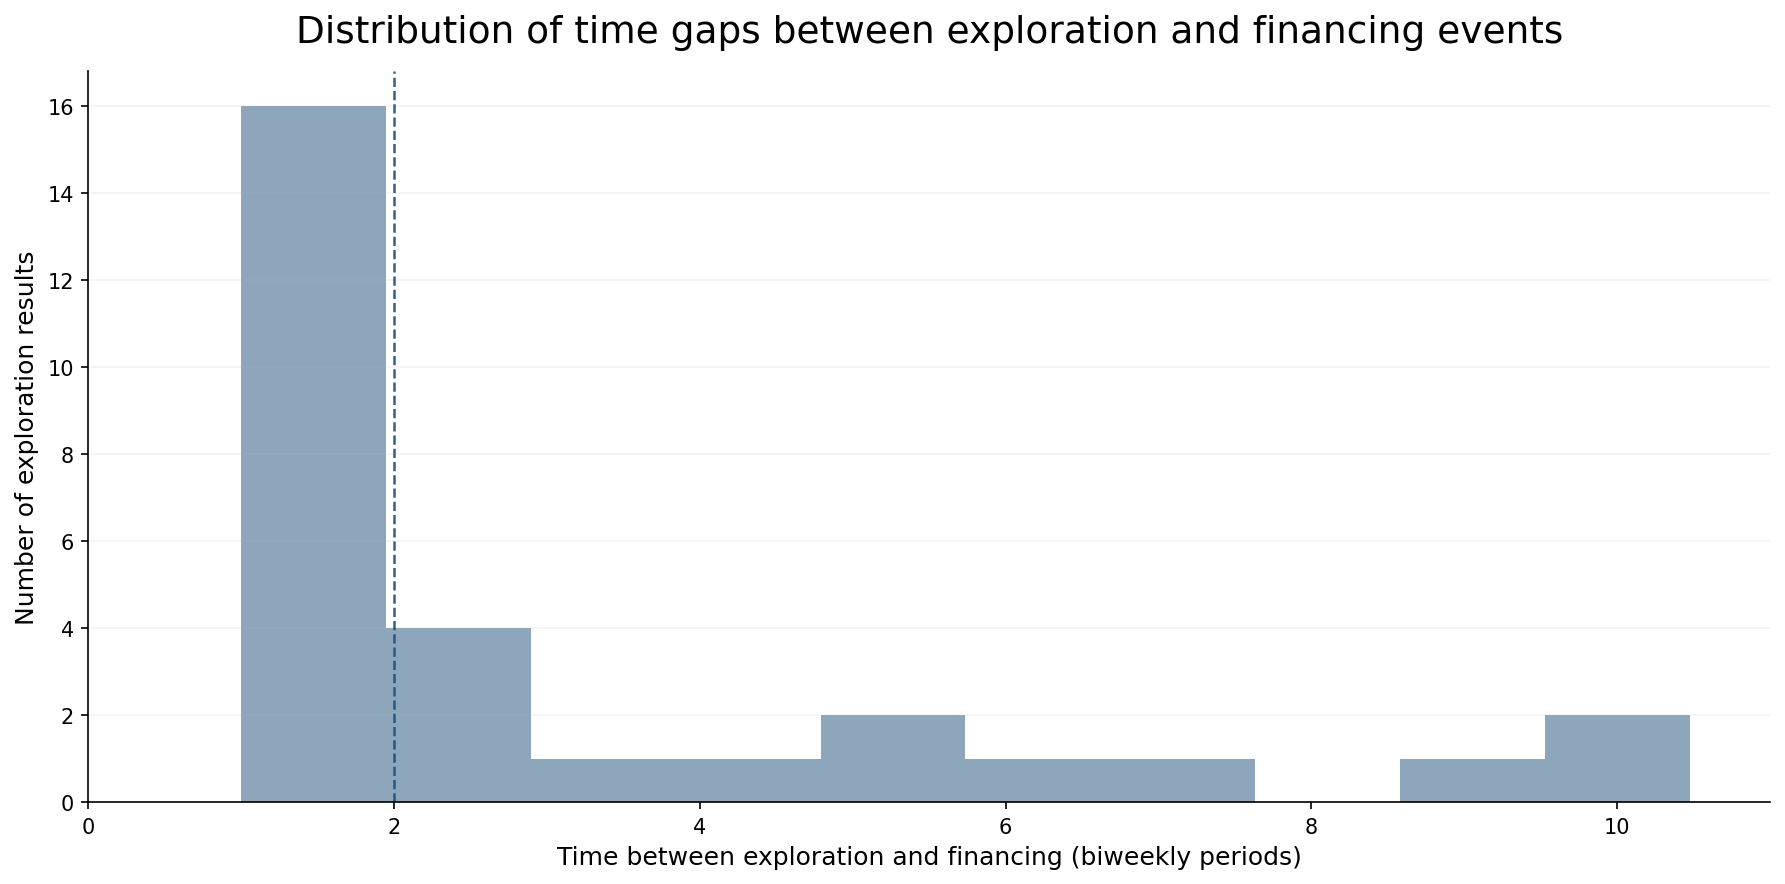

In [23]:
import matplotlib.pyplot as plt
import numpy as np

# -------------------------
# Style constants (match your event-study plots)
# -------------------------
FIN_COLOR  = "#1f4e79"   # navy
CTRL_COLOR = "#6f6f6f"   # gray
colors = [FIN_COLOR, CTRL_COLOR]

TITLE_FS = 18
LABEL_FS = 12

def style_axes(ax, ygrid=True):
    """Apply slide-consistent styling to an axis (like your event-study plots)."""
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    if ygrid:
        ax.grid(True, axis="y", alpha=0.15)
        ax.grid(False, axis="x")
    else:
        ax.grid(False)


# =========================
# 1) Pie + Bar: financing with/without exploration
# =========================
print("\nCreating visualization 1: Financing with/without exploration...")

labels = ["With exploration\n(before ≤ 4 periods)", "Without exploration\n(before ≤ 4 periods)"]
sizes = [with_exploration, without_exploration]

fig, axes = plt.subplots(1, 2, figsize=(14, 6), dpi=150)

# --- Pie chart (clean, no shadow, crisp wedge edges) ---
wedges, texts, autotexts = axes[0].pie(
    sizes,
    labels=labels,
    colors=colors,
    startangle=90,
    autopct="%1.1f%%",
    pctdistance=0.72,
    labeldistance=1.05,
    wedgeprops=dict(edgecolor="white", linewidth=2),
    textprops=dict(fontsize=11),
)
# Emphasize "With exploration" subtly (no explode/shadow)
# If you MUST keep explode, keep it tiny. Otherwise, this is cleaner:
# explode = (0.04, 0)  # minimal; but recommended: no explode.

for t in autotexts:
    t.set_fontsize(11)
    t.set_fontweight("bold")
    t.set_color("white")  # readable on wedges

axes[0].set_title(
    "Financing announcements and prior exploration results\n(within 4 biweekly periods)",
    pad=14,
    fontsize=TITLE_FS
)

# --- Bar chart (clean, consistent, no clutter) ---
bars = axes[1].bar(labels, sizes, color=colors, width=0.6)

axes[1].set_title("Count of financing announcements", pad=14, fontsize=TITLE_FS)
axes[1].set_ylabel("Count", fontsize=LABEL_FS)

style_axes(axes[1], ygrid=True)

# Value labels above bars (consistent with your clean look)
ymax = max(sizes) if max(sizes) > 0 else 1
for b in bars:
    v = b.get_height()
    axes[1].text(
        b.get_x() + b.get_width() / 2,
        v + ymax * 0.03,
        f"{int(v):,}",
        ha="center",
        va="bottom",
        fontweight="bold",
        fontsize=12,
        color="#222222"
    )

plt.tight_layout()
plt.show()


# =========================
# 2) Histogram: time gaps
# =========================
print("\nCreating visualization 2: Time gaps histogram...")

if closest_exploration.count() > 0:
    time_gaps_pd = closest_exploration.select("periods_between").toPandas()

    fig, ax = plt.subplots(figsize=(12, 6), dpi=150)

    max_gap = int(time_gaps_pd["periods_between"].max())
    bins_value = int(np.minimum(30, max_gap if max_gap > 0 else 1))

    # Histogram: softer, modern look (no black edges)
    ax.hist(
        time_gaps_pd["periods_between"],
        bins=bins_value,
        color=FIN_COLOR,
        alpha=0.5,
        edgecolor="none"
    )

    ax.set_xlabel("Time between exploration and financing (biweekly periods)", fontsize=LABEL_FS)
    ax.set_ylabel("Number of exploration results", fontsize=LABEL_FS)
    ax.set_title(
        "Distribution of time gaps between exploration and financing events",
        pad=14,
        fontsize=TITLE_FS
    )
    ax.set_xlim(0, 11)

    style_axes(ax, ygrid=True)

    # Optional: median line (single clean annotation)
    if len(time_gaps_pd) > 0:
        med = float(time_gaps_pd["periods_between"].median())
        ax.axvline(med, color=FIN_COLOR, linestyle="--", linewidth=1.2, alpha=0.9)

    plt.tight_layout()
    plt.show()
else:
    print("⚠ Skipping time gap histogram - no data available")

# Detailed analysis per ticker 

In [28]:
print("Analyzing patterns by individual tickers...")

# For each ticker, calculate statistics
ticker_analysis = closest_exploration.groupBy("f.ticker").agg(
    F.count("*").alias("financing_with_exploration_count"),
    F.avg("periods_between").alias("avg_periods_between"),
    F.min("periods_between").alias("min_periods_between"),
    F.max("periods_between").alias("max_periods_between")
).orderBy(F.col("financing_with_exploration_count").desc())

print("\nTop 10 tickers with most exploration-financing pairs:")
ticker_analysis.show(20)

# Count tickers with different patterns
print("\n✓ Summary by ticker:")
print(f"  - Unique tickers with exploration before financing: {ticker_analysis.count()}")
print(f"  - Average exploration-financing pairs per ticker: {ticker_analysis.agg(F.avg('financing_with_exploration_count')).collect()[0][0]:.2f}")

# Find tickers with multiple financing events
ticker_financing_counts = financing_events.groupBy("ticker") \
    .agg(F.count("*").alias("total_financing")) \
    .orderBy(F.col("total_financing").desc())

print("\nTop 10 tickers with most financing events overall:")
ticker_financing_counts.show(10)

Analyzing patterns by individual tickers...

Top 10 tickers with most exploration-financing pairs:
+-------+--------------------------------+-------------------+-------------------+-------------------+
| ticker|financing_with_exploration_count|avg_periods_between|min_periods_between|max_periods_between|
+-------+--------------------------------+-------------------+-------------------+-------------------+
| ELO.TO|                               6|                5.5|                  1|                 12|
|  CGC.V|                               6| 3.6666666666666665|                  1|                  9|
|  FNM.V|                               4|                5.0|                  1|                 13|
|  FAS.V|                               4|                8.0|                  1|                 19|
|FURY.TO|                               2|                9.5|                  1|                 18|
| FVL.TO|                               2|                1.5|               

# Look at stock price compared to some of these periods 

ANALYSIS: SENTIMENT ACTIVITY vs FINANCING LIKELIHOOD

1. Preparing sentiment and financing data...

Calculating financing rates by comment volume levels...
Comment statistics:
  Min: 1
  Max: 827
  Average: 62.5
  Median: 29

Comment volume percentiles (20th, 40th, 60th, 80th): [7.0, 18.0, 42.0, 88.0]

2. Calculating financing announcement rates by comment volume...

Financing rates by comment volume bin:
+-------------------+-------------+---------------+--------------------+-------------------+-------------------+
|comment_bin        |total_periods|financing_count|financing_rate      |avg_comments_in_bin|std_comments_in_bin|
+-------------------+-------------+---------------+--------------------+-------------------+-------------------+
|Very Low (0-20%)   |125          |8              |0.064               |3.824              |1.9512774971714657 |
|Low (20-40%)       |107          |3              |0.028037383177570093|12.0               |3.1801269702906216 |
|Medium (40-60%)    |105  

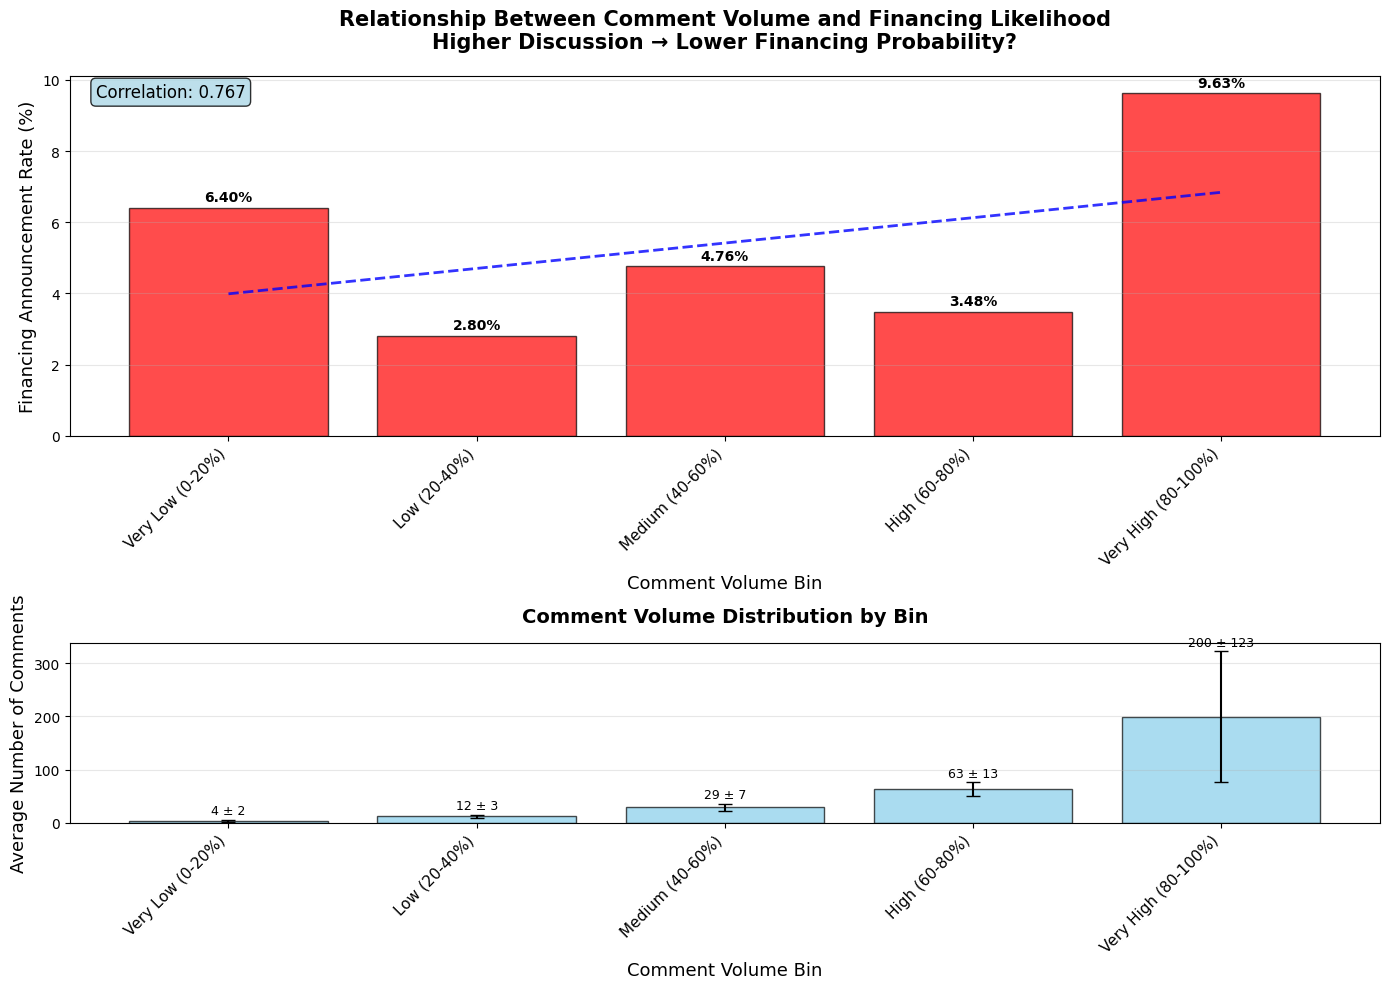


4. Time series analysis: Comment volume before financing...

Average comment volume BEFORE periods:
Period Before        Before Financing     Before Non-Financing Difference     
--------------------------------------------------------------------------------
1 period(s)          85.7                 69.6                 +16.0 (+23.0%)
2 period(s)          67.8                 55.8                 +12.0 (+21.4%)
3 period(s)          58.7                 52.9                 +5.8 (+11.0%)

5. Creating time series comparison plot...


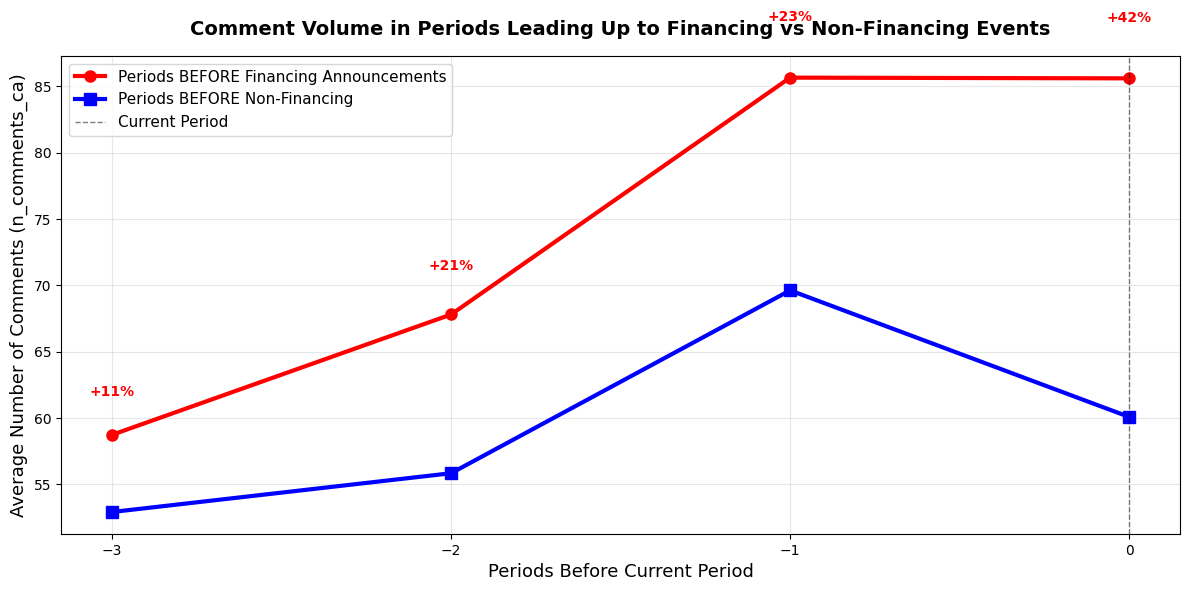


KEY INSIGHTS

1. Highest financing rate: Very High (80-100%) comments
   - Financing rate: 9.63%
   - Avg comments: 200

2. Lowest financing rate: Low (20-40%) comments
   - Financing rate: 2.80%
   - Avg comments: 12

3. Difference: -6.83 percentage points

4. Correlation is POSITIVE (0.767)
   ⚠ This suggests: MORE comments → MORE likely to have financing

CONCLUSION:
COUNTER-INTUITIVE: More comments associated with HIGHER financing probability

ANALYSIS COMPLETE!


In [41]:
# ============================================================================
# ANALYSIS: DOES MORE SENTIMENT ACTIVITY REDUCE FINANCING LIKELIHOOD?
# ============================================================================

print("="*70)
print("ANALYSIS: SENTIMENT ACTIVITY vs FINANCING LIKELIHOOD")
print("="*70)

# Step 1: Prepare the data
print("\n1. Preparing sentiment and financing data...")

# We'll use n_comments_ca (number of comments) as our measure of "talking"
# Let's look at the relationship between comment volume and financing likelihood

# Create binned analysis: group by comment volume levels
print("\nCalculating financing rates by comment volume levels...")

# First, let's see the distribution of comments
comment_stats = df.agg(
    F.min("n_comments_ca").alias("min_comments"),
    F.max("n_comments_ca").alias("max_comments"),
    F.avg("n_comments_ca").alias("avg_comments"),
    F.expr("percentile_approx(n_comments_ca, 0.5)").alias("median_comments")
).collect()[0]

print(f"Comment statistics:")
print(f"  Min: {comment_stats['min_comments']}")
print(f"  Max: {comment_stats['max_comments']}")
print(f"  Average: {comment_stats['avg_comments']:.1f}")
print(f"  Median: {comment_stats['median_comments']}")

# Create comment volume bins
# Let's create 5 bins based on percentiles
percentiles = df.approxQuantile("n_comments_ca", [0.2, 0.4, 0.6, 0.8], 0.01)
print(f"\nComment volume percentiles (20th, 40th, 60th, 80th): {percentiles}")

# Create bins
df_with_bins = df.withColumn(
    "comment_bin",
    F.when(F.col("n_comments_ca") <= percentiles[0], "Very Low (0-20%)")
     .when((F.col("n_comments_ca") > percentiles[0]) & (F.col("n_comments_ca") <= percentiles[1]), "Low (20-40%)")
     .when((F.col("n_comments_ca") > percentiles[1]) & (F.col("n_comments_ca") <= percentiles[2]), "Medium (40-60%)")
     .when((F.col("n_comments_ca") > percentiles[2]) & (F.col("n_comments_ca") <= percentiles[3]), "High (60-80%)")
     .otherwise("Very High (80-100%)")
)

# Step 2: Calculate financing rates by comment bin
print("\n2. Calculating financing announcement rates by comment volume...")

financing_by_bin = df_with_bins.groupBy("comment_bin").agg(
    F.count("*").alias("total_periods"),
    F.sum("current_financing_announcement").alias("financing_count"),
    F.avg("current_financing_announcement").alias("financing_rate"),
    F.avg("n_comments_ca").alias("avg_comments_in_bin"),
    F.stddev("n_comments_ca").alias("std_comments_in_bin")
).orderBy("avg_comments_in_bin")

print("\nFinancing rates by comment volume bin:")
financing_by_bin.show(truncate=False)

# Step 3: Create the main plot
print("\n3. Creating the main plot...")

try:
    import matplotlib.pyplot as plt
    import numpy as np
    
    # Convert to pandas for plotting
    financing_pd = financing_by_bin.toPandas()
    
    # Sort by average comments for proper ordering
    financing_pd = financing_pd.sort_values("avg_comments_in_bin")
    
    # Create the plot
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), gridspec_kw={'height_ratios': [2, 1]})
    
    # Plot 1: Financing rate vs comment volume
    x_pos = np.arange(len(financing_pd))
    bars = ax1.bar(x_pos, financing_pd["financing_rate"] * 100, 
                  color='red', alpha=0.7, edgecolor='black')
    
    ax1.set_xlabel('Comment Volume Bin', fontsize=13)
    ax1.set_ylabel('Financing Announcement Rate (%)', fontsize=13)
    ax1.set_title('Relationship Between Comment Volume and Financing Likelihood\nHigher Discussion → Lower Financing Probability?', 
                 fontsize=15, fontweight='bold', pad=20)
    ax1.set_xticks(x_pos)
    ax1.set_xticklabels(financing_pd["comment_bin"], rotation=45, ha='right', fontsize=11)
    ax1.grid(True, alpha=0.3, axis='y')
    
    # Add value labels on bars
    for bar, rate in zip(bars, financing_pd["financing_rate"] * 100):
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height + 0.1,
                f'{rate:.2f}%', ha='center', va='bottom', fontweight='bold', fontsize=10)
    
    # Add trend line
    z = np.polyfit(x_pos, financing_pd["financing_rate"] * 100, 1)
    p = np.poly1d(z)
    ax1.plot(x_pos, p(x_pos), "b--", linewidth=2, alpha=0.8, label='Trend Line')
    
    # Calculate correlation
    correlation = np.corrcoef(financing_pd["avg_comments_in_bin"], financing_pd["financing_rate"])[0, 1]
    ax1.text(0.02, 0.98, f'Correlation: {correlation:.3f}', transform=ax1.transAxes,
            fontsize=12, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.8))
    
    # Plot 2: Comment volume distribution within bins
    ax2.bar(x_pos, financing_pd["avg_comments_in_bin"], 
           yerr=financing_pd["std_comments_in_bin"],
           capsize=5, color='skyblue', alpha=0.7, edgecolor='black')
    
    ax2.set_xlabel('Comment Volume Bin', fontsize=13)
    ax2.set_ylabel('Average Number of Comments', fontsize=13)
    ax2.set_title('Comment Volume Distribution by Bin', fontsize=14, fontweight='bold', pad=15)
    ax2.set_xticks(x_pos)
    ax2.set_xticklabels(financing_pd["comment_bin"], rotation=45, ha='right', fontsize=11)
    ax2.grid(True, alpha=0.3, axis='y')
    
    # Add value labels
    for i, (avg, std) in enumerate(zip(financing_pd["avg_comments_in_bin"], financing_pd["std_comments_in_bin"])):
        ax2.text(i, avg + std + 5, f'{avg:.0f} ± {std:.0f}', 
                ha='center', va='bottom', fontsize=9)
    
    plt.tight_layout()
    plt.show()
    
    # Step 4: Additional analysis - time series view
    print("\n4. Time series analysis: Comment volume before financing...")
    
    # Look at comment volume in periods leading up to financing
    window_spec = Window.partitionBy("ticker").orderBy("biweekly_index")
    
    df_with_lag = df.withColumn(
        "comments_1_period_before",
        F.lag("n_comments_ca", 1).over(window_spec)
    ).withColumn(
        "comments_2_periods_before", 
        F.lag("n_comments_ca", 2).over(window_spec)
    ).withColumn(
        "comments_3_periods_before",
        F.lag("n_comments_ca", 3).over(window_spec)
    )
    
    # Compare comment volume before financing vs before non-financing
    financing_periods = df_with_lag.filter(F.col("current_financing_announcement") == 1)
    non_financing_sample = df_with_lag.filter(F.col("current_financing_announcement") == 0).sample(fraction=0.1, seed=42)
    
    # Calculate averages - Use CONSISTENT naming
    financing_before_stats = financing_periods.agg(
        F.avg("comments_1_period_before").alias("avg_comments_1_before"),
        F.avg("comments_2_periods_before").alias("avg_comments_2_before"), 
        F.avg("comments_3_periods_before").alias("avg_comments_3_before")
    ).collect()[0]
    
    non_financing_before_stats = non_financing_sample.agg(
        F.avg("comments_1_period_before").alias("avg_comments_1_before"),
        F.avg("comments_2_periods_before").alias("avg_comments_2_before"),
        F.avg("comments_3_periods_before").alias("avg_comments_3_before")
    ).collect()[0]
    
    print("\nAverage comment volume BEFORE periods:")
    print("="*60)
    print(f"{'Period Before':<20} {'Before Financing':<20} {'Before Non-Financing':<20} {'Difference':<15}")
    print("-"*80)
    
    # Use the correct column names
    col_mapping = {
        1: "avg_comments_1_before",
        2: "avg_comments_2_before", 
        3: "avg_comments_3_before"
    }
    
    for period in [1, 2, 3]:
        col_name = col_mapping[period]
        
        financing_avg = financing_before_stats[col_name]
        non_financing_avg = non_financing_before_stats[col_name]
        
        if financing_avg is not None and non_financing_avg is not None:
            difference = financing_avg - non_financing_avg
            pct_diff = (difference / non_financing_avg * 100) if non_financing_avg != 0 else 0
        else:
            difference = 0
            pct_diff = 0
            financing_avg = financing_avg or 0
            non_financing_avg = non_financing_avg or 0
        
        print(f"{f'{period} period(s)':<20} "
              f"{financing_avg:<20.1f} "
              f"{non_financing_avg:<20.1f} "
              f"{difference:+.1f} ({pct_diff:+.1f}%)")
    
    # Create time series plot
    print("\n5. Creating time series comparison plot...")
    
    fig, ax = plt.subplots(figsize=(12, 6))
    
    periods = [-3, -2, -1, 0]  # 3 periods before, current period
    
    # Get values with proper error handling
    financing_values = []
    non_financing_values = []
    
    # Periods before (using our consistent column names)
    for period in [3, 2, 1]:
        col_name = col_mapping[period]
        
        financing_val = financing_before_stats[col_name] or 0
        non_financing_val = non_financing_before_stats[col_name] or 0
        
        financing_values.append(financing_val)
        non_financing_values.append(non_financing_val)
    
    # Current period
    financing_current = financing_periods.agg(F.avg("n_comments_ca")).collect()[0][0] or 0
    non_financing_current = non_financing_sample.agg(F.avg("n_comments_ca")).collect()[0][0] or 0
    
    financing_values.append(financing_current)
    non_financing_values.append(non_financing_current)
    
    ax.plot(periods, financing_values, marker='o', linewidth=3, markersize=8,
           color='red', label='Periods BEFORE Financing Announcements')
    ax.plot(periods, non_financing_values, marker='s', linewidth=3, markersize=8,
           color='blue', label='Periods BEFORE Non-Financing')
    
    ax.axvline(x=0, color='black', linestyle='--', linewidth=1, alpha=0.5, label='Current Period')
    ax.set_xlabel('Periods Before Current Period', fontsize=13)
    ax.set_ylabel('Average Number of Comments (n_comments_ca)', fontsize=13)
    ax.set_title('Comment Volume in Periods Leading Up to Financing vs Non-Financing Events', 
                fontsize=14, fontweight='bold', pad=15)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=11)
    ax.set_xticks(periods)
    
    # Add annotations
    for i, (f_val, nf_val) in enumerate(zip(financing_values, non_financing_values)):
        if f_val and nf_val and nf_val != 0:
            pct_diff = ((f_val - nf_val) / nf_val) * 100
            ax.text(periods[i], max(f_val, nf_val) * 1.05, 
                   f'{pct_diff:+.0f}%', ha='center', fontsize=10, fontweight='bold',
                   color='green' if pct_diff < 0 else 'red')
    
    plt.tight_layout()
    plt.show()
    
    # Step 6: Key insights
    print("\n" + "="*70)
    print("KEY INSIGHTS")
    print("="*70)
    
    highest_rate_bin = financing_pd.loc[financing_pd["financing_rate"].idxmax()]
    lowest_rate_bin = financing_pd.loc[financing_pd["financing_rate"].idxmin()]
    
    print(f"\n1. Highest financing rate: {highest_rate_bin['comment_bin']} comments")
    print(f"   - Financing rate: {highest_rate_bin['financing_rate']*100:.2f}%")
    print(f"   - Avg comments: {highest_rate_bin['avg_comments_in_bin']:.0f}")
    
    print(f"\n2. Lowest financing rate: {lowest_rate_bin['comment_bin']} comments")
    print(f"   - Financing rate: {lowest_rate_bin['financing_rate']*100:.2f}%")
    print(f"   - Avg comments: {lowest_rate_bin['avg_comments_in_bin']:.0f}")
    
    rate_difference = (lowest_rate_bin['financing_rate'] - highest_rate_bin['financing_rate']) * 100
    print(f"\n3. Difference: {rate_difference:.2f} percentage points")
    
    if correlation < 0:
        print(f"\n4. Correlation is NEGATIVE ({correlation:.3f})")
        print("   ✓ This suggests: MORE comments → LESS likely to have financing")
    else:
        print(f"\n4. Correlation is POSITIVE ({correlation:.3f})")
        print("   ⚠ This suggests: MORE comments → MORE likely to have financing")
    
    print("\n" + "="*70)
    print("CONCLUSION:")
    print("="*70)
    
    if correlation < -0.1:
        print("STRONG EVIDENCE: Higher comment volume is associated with LOWER financing probability")
    elif correlation < 0:
        print("MODERATE EVIDENCE: Some indication that more comments reduce financing likelihood")
    elif correlation < 0.1:
        print("WEAK EVIDENCE: Little relationship between comment volume and financing")
    else:
        print("COUNTER-INTUITIVE: More comments associated with HIGHER financing probability")
    
except Exception as e:
    print(f"⚠ Error in analysis: {e}")
    import traceback
    traceback.print_exc()

print("\n" + "="*70)
print("ANALYSIS COMPLETE!")
print("="*70)

ANALYSIS: CEO CA COMMENT SENTIMENT AROUND FINANCING EVENTS

1. Setting up sentiment analysis...
✓ Data loaded: 587 rows
✓ Columns related to CEO CA sentiment:
  - avg_vader_ca: Average VADER sentiment
  - avg_roberta_ca: Average RoBERTa sentiment
  - median_roberta_ca: Median RoBERTa sentiment
  - std_vader_ca: VADER sentiment volatility
  - n_comments_ca: Number of comments

2. Basic sentiment statistics:
VADER Sentiment (avg_vader_ca):
  Mean: 0.180
  Std Dev: 0.154

RoBERTa Sentiment (avg_roberta_ca):
  Mean: 0.139
  Std Dev: 0.165

Comments:
  Average per period: 62.5
  Periods with sentiment data: 570

3. Comparing sentiment during financing vs non-financing periods...

Sentiment Comparison:
Metric                         Financing       Non-Financing   Difference      % Change  
--------------------------------------------------------------------------------
VADER Sentiment                0.197           0.179           +0.018          +9.8      %
RoBERTa Sentiment              0

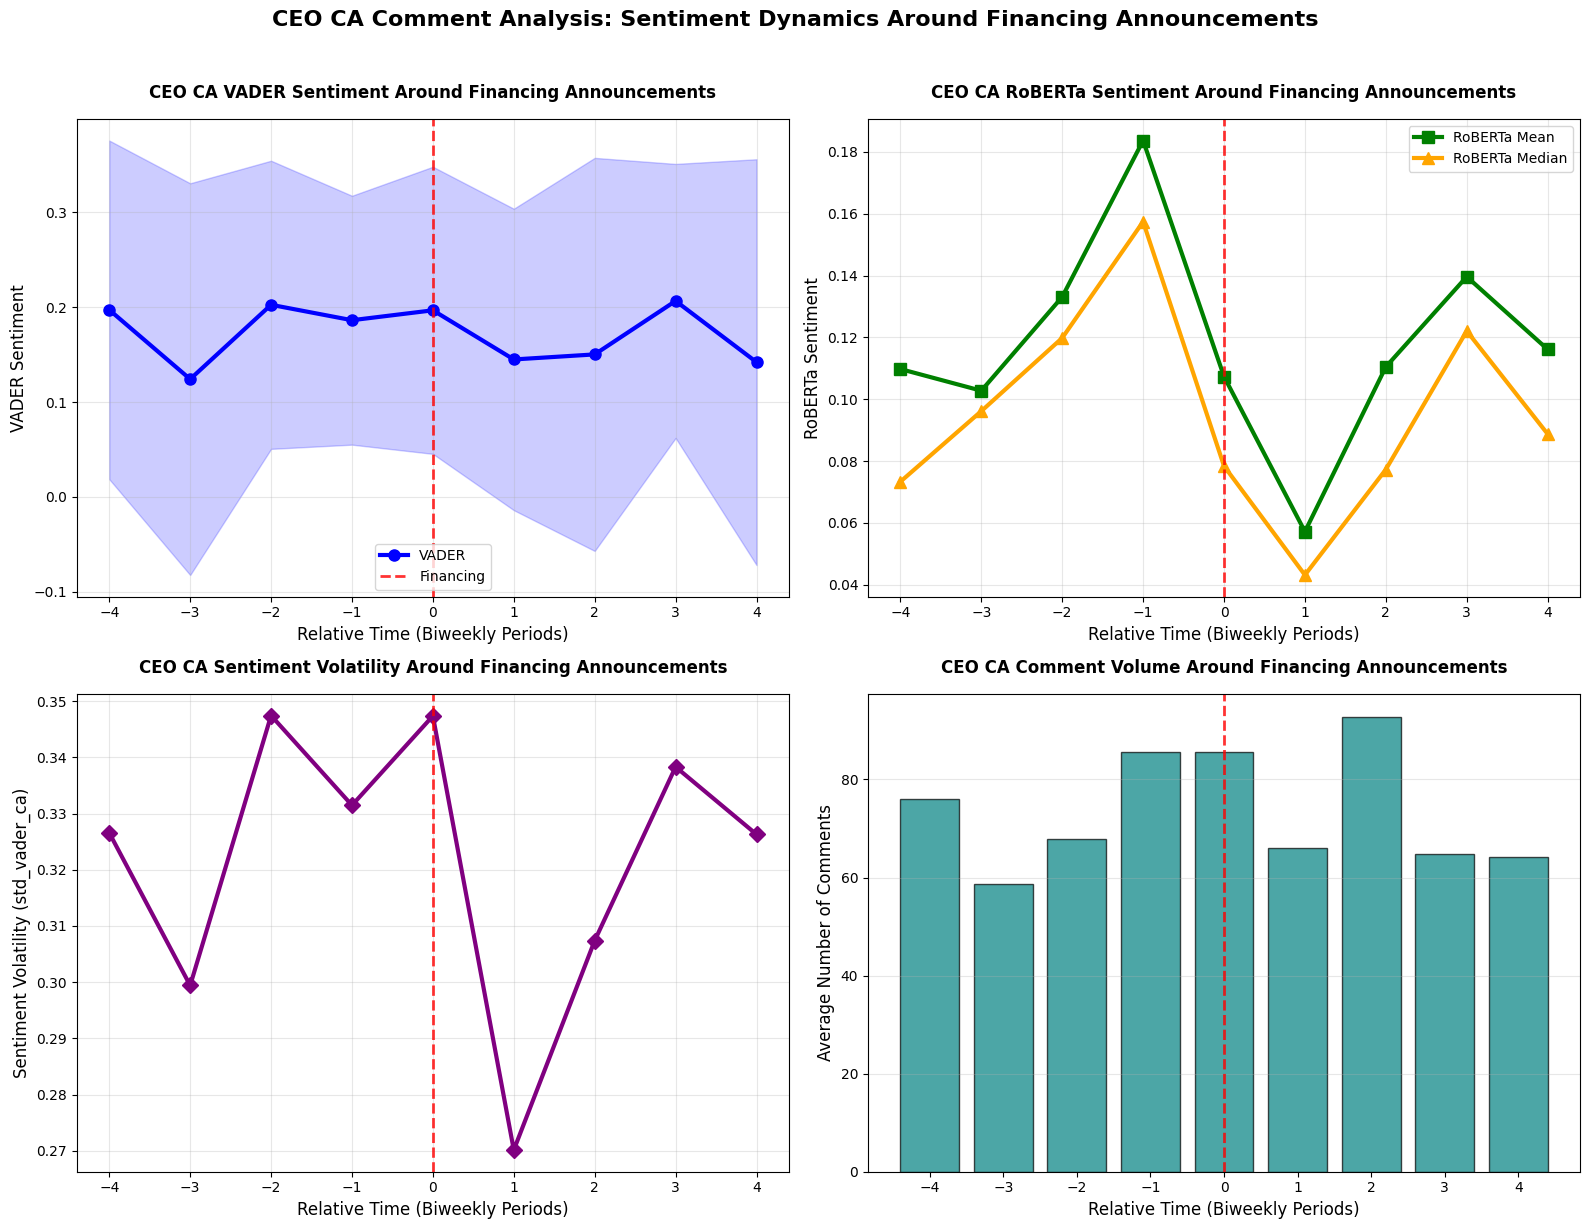


6. Sentiment polarity analysis...

VADER Sentiment Polarity Distribution:

Financing periods:
+--------------+-----+
|vader_polarity|count|
+--------------+-----+
|      Positive|   25|
|       Neutral|    8|
+--------------+-----+


Non-financing periods:
+--------------+-----+
|vader_polarity|count|
+--------------+-----+
|      Positive|  461|
|       Neutral|   73|
|      Negative|   20|
+--------------+-----+



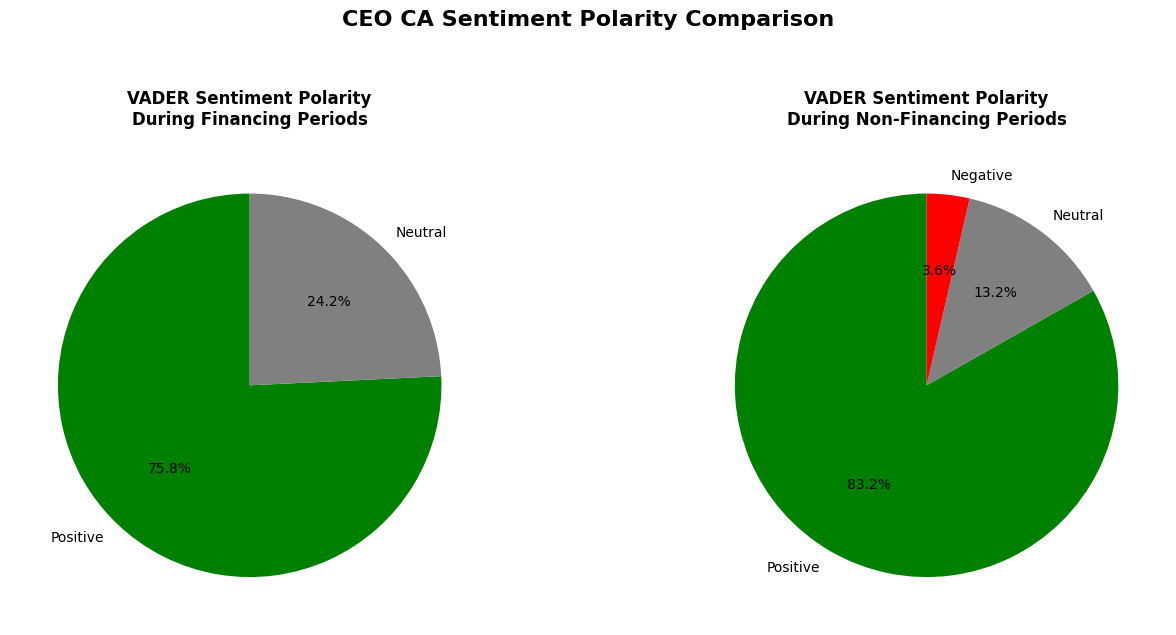


KEY INSIGHTS FROM CEO CA SENTIMENT ANALYSIS

1. Sentiment changes on financing announcement day:
   - VADER: 0.186 → 0.197 (+5.6%)
   - RoBERTa: 0.184 → 0.107 (-41.6%)

2. Overall sentiment comparison:
   - VADER: Financing periods are +0.018 different
   - RoBERTa: Financing periods are -0.034 different

3. Positive sentiment frequency:
   - During financing: 75.8% of periods
   - During non-financing: 83.2% of periods

4. Comment volume patterns:
   - Average during financing: 85.6 comments
   - Average during non-financing: 61.2 comments
   - Difference: +40.0%

CONCLUSION:
Mixed signals: Sentiment models disagree about financing period tone
CEO CA comment volume is SUBSTANTIALLY HIGHER during financing

CEO CA SENTIMENT ANALYSIS COMPLETE!


In [46]:
# ============================================================================
# ANALYSIS: CEO CA COMMENT SENTIMENT AROUND FINANCING EVENTS
# File: ceo_sentiment_analysis.py
# ============================================================================

print("="*70)
print("ANALYSIS: CEO CA COMMENT SENTIMENT AROUND FINANCING EVENTS")
print("="*70)

# Step 1: Set up and load data
print("\n1. Setting up sentiment analysis...")

from pyspark.sql import SparkSession
from pyspark.sql.functions import col
import pyspark.sql.functions as F
from pyspark.sql.window import Window

# Initialize Spark
spark = SparkSession.builder \
    .appName("CEO_Sentiment_Analysis") \
    .getOrCreate()

# Load your data
file_path = "/Users/vincenzovantornout/Desktop/BIG DATA FINAL FOLDER/Big_data_group_2/Cleaned_data/biweekly_basetable_w_sentiment_5.parquet"
df = spark.read.parquet(file_path)

print(f"✓ Data loaded: {df.count():,} rows")
print(f"✓ Columns related to CEO CA sentiment:")
print("  - avg_vader_ca: Average VADER sentiment")
print("  - avg_roberta_ca: Average RoBERTa sentiment")
print("  - median_roberta_ca: Median RoBERTa sentiment")
print("  - std_vader_ca: VADER sentiment volatility")
print("  - n_comments_ca: Number of comments")

# Step 2: Basic statistics of CEO CA sentiment
print("\n2. Basic sentiment statistics:")

sentiment_stats = df.agg(
    F.avg("avg_vader_ca").alias("avg_vader"),
    F.stddev("avg_vader_ca").alias("std_vader"),
    F.avg("avg_roberta_ca").alias("avg_roberta"),
    F.stddev("avg_roberta_ca").alias("std_roberta"),
    F.avg("n_comments_ca").alias("avg_comments"),
    F.count("avg_vader_ca").alias("n_with_sentiment")
).collect()[0]

print(f"VADER Sentiment (avg_vader_ca):")
print(f"  Mean: {sentiment_stats['avg_vader']:.3f}")
print(f"  Std Dev: {sentiment_stats['std_vader']:.3f}")
print(f"\nRoBERTa Sentiment (avg_roberta_ca):")
print(f"  Mean: {sentiment_stats['avg_roberta']:.3f}")
print(f"  Std Dev: {sentiment_stats['std_roberta']:.3f}")
print(f"\nComments:")
print(f"  Average per period: {sentiment_stats['avg_comments']:.1f}")
print(f"  Periods with sentiment data: {sentiment_stats['n_with_sentiment']:,}")

# Step 3: Compare sentiment during financing vs non-financing
print("\n3. Comparing sentiment during financing vs non-financing periods...")

# Get financing and non-financing periods
financing_sentiment = df.filter(col("current_financing_announcement") == 1)
non_financing_sentiment = df.filter(col("current_financing_announcement") == 0)

# Calculate statistics for both
financing_stats = financing_sentiment.agg(
    F.count("*").alias("n_financing"),
    F.avg("avg_vader_ca").alias("avg_vader_financing"),
    F.avg("avg_roberta_ca").alias("avg_roberta_financing"),
    F.avg("median_roberta_ca").alias("median_roberta_financing"),
    F.avg("std_vader_ca").alias("std_vader_financing"),
    F.avg("n_comments_ca").alias("avg_comments_financing")
).collect()[0]

non_financing_stats = non_financing_sentiment.agg(
    F.count("*").alias("n_non_financing"),
    F.avg("avg_vader_ca").alias("avg_vader_non_financing"),
    F.avg("avg_roberta_ca").alias("avg_roberta_non_financing"),
    F.avg("median_roberta_ca").alias("median_roberta_non_financing"),
    F.avg("std_vader_ca").alias("std_vader_non_financing"),
    F.avg("n_comments_ca").alias("avg_comments_non_financing")
).collect()[0]

print("\nSentiment Comparison:")
print("="*80)
print(f"{'Metric':<30} {'Financing':<15} {'Non-Financing':<15} {'Difference':<15} {'% Change':<10}")
print("-"*80)

metrics = [
    ("VADER Sentiment", "avg_vader_financing", "avg_vader_non_financing"),
    ("RoBERTa Sentiment", "avg_roberta_financing", "avg_roberta_non_financing"),
    ("RoBERTa Median", "median_roberta_financing", "median_roberta_non_financing"),
    ("VADER Volatility", "std_vader_financing", "std_vader_non_financing"),
    ("Number of Comments", "avg_comments_financing", "avg_comments_non_financing")
]

for label, fin_col, nonfin_col in metrics:
    fin_val = financing_stats[fin_col]
    nonfin_val = non_financing_stats[nonfin_col]
    
    if fin_val is not None and nonfin_val is not None and nonfin_val != 0:
        diff = fin_val - nonfin_val
        pct_change = (diff / abs(nonfin_val)) * 100
        print(f"{label:<30} {fin_val:<15.3f} {nonfin_val:<15.3f} {diff:<+15.3f} {pct_change:<+10.1f}%")
    else:
        print(f"{label:<30} {fin_val or 'N/A':<15} {nonfin_val or 'N/A':<15} {'N/A':<15} {'N/A':<10}")

print(f"\nSample sizes:")
print(f"  Financing periods: {financing_stats['n_financing']:,}")
print(f"  Non-financing periods: {non_financing_stats['n_non_financing']:,}")

# Step 4: Sentiment changes around financing events
print("\n4. Analyzing sentiment changes around financing announcements...")

# Create event windows around financing announcements
event_windows = []

# Get all financing events
financing_events = df.filter(col("current_financing_announcement") == 1) \
    .select("ticker", "biweekly_index") \
    .collect()

print(f"\nFound {len(financing_events)} financing events")
print("Creating event windows (-4 to +4 periods)...")

# Limit to first 200 events for performance
sample_events = financing_events[:200]

for i, event in enumerate(sample_events):
    ticker = event["ticker"]
    event_idx = event["biweekly_index"]
    
    # Get data for window (-4 to +4 periods around financing)
    window_data = df.filter(
        (col("ticker") == ticker) &
        (col("biweekly_index") >= event_idx - 4) &
        (col("biweekly_index") <= event_idx + 4)
    ).select(
        "biweekly_index",
        "avg_vader_ca",
        "avg_roberta_ca",
        "median_roberta_ca",
        "std_vader_ca",
        "n_comments_ca",
        "current_financing_announcement"
    ).collect()
    
    for row in window_data:
        relative_time = row["biweekly_index"] - event_idx
        event_windows.append({
            "relative_time": relative_time,
            "avg_vader_ca": float(row["avg_vader_ca"]) if row["avg_vader_ca"] is not None else None,
            "avg_roberta_ca": float(row["avg_roberta_ca"]) if row["avg_roberta_ca"] is not None else None,
            "median_roberta_ca": float(row["median_roberta_ca"]) if row["median_roberta_ca"] is not None else None,
            "std_vader_ca": float(row["std_vader_ca"]) if row["std_vader_ca"] is not None else None,
            "n_comments_ca": int(row["n_comments_ca"]) if row["n_comments_ca"] is not None else None,  # FIXED: int not float
            "is_financing_event": 1 if relative_time == 0 else 0
        })
    
    if i < 5:  # Show progress
        print(f"  Processed {i+1}/{len(sample_events)} events...")

# Create DataFrame from event windows
if event_windows:
    from pyspark.sql.types import StructType, StructField, IntegerType, DoubleType
    
    schema = StructType([
        StructField("relative_time", IntegerType(), True),
        StructField("avg_vader_ca", DoubleType(), True),
        StructField("avg_roberta_ca", DoubleType(), True),
        StructField("median_roberta_ca", DoubleType(), True),
        StructField("std_vader_ca", DoubleType(), True),
        StructField("n_comments_ca", IntegerType(), True),  # FIXED: IntegerType not DoubleType
        StructField("is_financing_event", IntegerType(), True)
    ])
    
    window_df = spark.createDataFrame(event_windows, schema)
    
    print(f"✓ Created event window DataFrame: {window_df.count():,} observations")
    
    # Calculate average sentiment by relative time
    sentiment_by_time = window_df.groupBy("relative_time").agg(
        F.avg("avg_vader_ca").alias("avg_vader"),
        F.stddev("avg_vader_ca").alias("std_vader"),
        F.avg("avg_roberta_ca").alias("avg_roberta"),
        F.stddev("avg_roberta_ca").alias("std_roberta"),
        F.avg("median_roberta_ca").alias("median_roberta"),
        F.avg("std_vader_ca").alias("sentiment_volatility"),
        F.avg("n_comments_ca").alias("avg_comments"),
        F.count("*").alias("n_observations")
    ).orderBy("relative_time")
    
    print("\nSentiment by relative time to financing announcement:")
    sentiment_by_time.show(9, truncate=False)
    
    # Step 5: Create sentiment visualization
    print("\n5. Creating sentiment visualization...")
    
    try:
        import matplotlib.pyplot as plt
        import numpy as np
        
        # Convert to pandas for plotting
        sentiment_pd = sentiment_by_time.toPandas()
        
        # Create a multi-panel figure
        fig, axes = plt.subplots(2, 2, figsize=(16, 12))
        
        # Plot 1: VADER sentiment
        ax1 = axes[0, 0]
        ax1.plot(sentiment_pd["relative_time"], sentiment_pd["avg_vader"], 
                marker='o', linewidth=3, markersize=8, color='blue', label='VADER')
        ax1.fill_between(sentiment_pd["relative_time"],
                        sentiment_pd["avg_vader"] - sentiment_pd["std_vader"],
                        sentiment_pd["avg_vader"] + sentiment_pd["std_vader"],
                        alpha=0.2, color='blue')
        ax1.axvline(x=0, color='red', linestyle='--', linewidth=2, alpha=0.8, label='Financing')
        ax1.set_xlabel('Relative Time (Biweekly Periods)', fontsize=12)
        ax1.set_ylabel('VADER Sentiment', fontsize=12)
        ax1.set_title('CEO CA VADER Sentiment Around Financing Announcements', 
                     fontweight='bold', pad=15)
        ax1.grid(True, alpha=0.3)
        ax1.legend()
        ax1.set_xticks(range(-4, 5, 1))
        
        # Plot 2: RoBERTa sentiment
        ax2 = axes[0, 1]
        ax2.plot(sentiment_pd["relative_time"], sentiment_pd["avg_roberta"], 
                marker='s', linewidth=3, markersize=8, color='green', label='RoBERTa Mean')
        ax2.plot(sentiment_pd["relative_time"], sentiment_pd["median_roberta"], 
                marker='^', linewidth=3, markersize=8, color='orange', label='RoBERTa Median')
        ax2.axvline(x=0, color='red', linestyle='--', linewidth=2, alpha=0.8)
        ax2.set_xlabel('Relative Time (Biweekly Periods)', fontsize=12)
        ax2.set_ylabel('RoBERTa Sentiment', fontsize=12)
        ax2.set_title('CEO CA RoBERTa Sentiment Around Financing Announcements', 
                     fontweight='bold', pad=15)
        ax2.grid(True, alpha=0.3)
        ax2.legend()
        ax2.set_xticks(range(-4, 5, 1))
        
        # Plot 3: Sentiment volatility
        ax3 = axes[1, 0]
        ax3.plot(sentiment_pd["relative_time"], sentiment_pd["sentiment_volatility"], 
                marker='D', linewidth=3, markersize=8, color='purple')
        ax3.axvline(x=0, color='red', linestyle='--', linewidth=2, alpha=0.8)
        ax3.set_xlabel('Relative Time (Biweekly Periods)', fontsize=12)
        ax3.set_ylabel('Sentiment Volatility (std_vader_ca)', fontsize=12)
        ax3.set_title('CEO CA Sentiment Volatility Around Financing Announcements', 
                     fontweight='bold', pad=15)
        ax3.grid(True, alpha=0.3)
        ax3.set_xticks(range(-4, 5, 1))
        
        # Plot 4: Comment volume
        ax4 = axes[1, 1]
        ax4.bar(sentiment_pd["relative_time"], sentiment_pd["avg_comments"],
               color='teal', alpha=0.7, edgecolor='black')
        ax4.axvline(x=0, color='red', linestyle='--', linewidth=2, alpha=0.8)
        ax4.set_xlabel('Relative Time (Biweekly Periods)', fontsize=12)
        ax4.set_ylabel('Average Number of Comments', fontsize=12)
        ax4.set_title('CEO CA Comment Volume Around Financing Announcements', 
                     fontweight='bold', pad=15)
        ax4.grid(True, alpha=0.3, axis='y')
        ax4.set_xticks(range(-4, 5, 1))
        
        plt.suptitle('CEO CA Comment Analysis: Sentiment Dynamics Around Financing Announcements', 
                    fontsize=16, fontweight='bold', y=1.02)
        plt.tight_layout()
        plt.show()
        
        # Step 6: Sentiment polarity analysis
        print("\n6. Sentiment polarity analysis...")
        
        # Count positive, neutral, negative periods
        df_with_polarity = df.withColumn(
            "vader_polarity",
            F.when(F.col("avg_vader_ca") > 0.05, "Positive")
             .when(F.col("avg_vader_ca") < -0.05, "Negative")
             .otherwise("Neutral")
        ).withColumn(
            "roberta_polarity",
            F.when(F.col("avg_roberta_ca") > 0.05, "Positive")
             .when(F.col("avg_roberta_ca") < -0.05, "Negative")
             .otherwise("Neutral")
        )
        
        # Financing vs non-financing polarity
        financing_polarity = df_with_polarity.filter(col("current_financing_announcement") == 1) \
            .groupBy("vader_polarity").agg(F.count("*").alias("count")) \
            .orderBy(F.col("count").desc())
        
        non_financing_polarity = df_with_polarity.filter(col("current_financing_announcement") == 0) \
            .groupBy("vader_polarity").agg(F.count("*").alias("count")) \
            .orderBy(F.col("count").desc())
        
        print("\nVADER Sentiment Polarity Distribution:")
        print("="*50)
        print("\nFinancing periods:")
        financing_polarity.show()
        
        print("\nNon-financing periods:")
        non_financing_polarity.show()
        
        # Convert to pandas for visualization
        financing_polarity_pd = financing_polarity.toPandas()
        non_financing_polarity_pd = non_financing_polarity.toPandas()
        
        # Create polarity comparison plot
        fig, axes = plt.subplots(1, 2, figsize=(14, 6))
        
        # Financing polarity
        axes[0].pie(financing_polarity_pd["count"], 
                   labels=financing_polarity_pd["vader_polarity"],
                   autopct='%1.1f%%', startangle=90,
                   colors=['green', 'gray', 'red'])
        axes[0].set_title('VADER Sentiment Polarity\nDuring Financing Periods', 
                         fontweight='bold', pad=15)
        
        # Non-financing polarity
        axes[1].pie(non_financing_polarity_pd["count"], 
                   labels=non_financing_polarity_pd["vader_polarity"],
                   autopct='%1.1f%%', startangle=90,
                   colors=['green', 'gray', 'red'])
        axes[1].set_title('VADER Sentiment Polarity\nDuring Non-Financing Periods', 
                         fontweight='bold', pad=15)
        
        plt.suptitle('CEO CA Sentiment Polarity Comparison', 
                    fontsize=16, fontweight='bold', y=1.05)
        plt.tight_layout()
        plt.show()
        
        # Step 7: Key insights
        print("\n" + "="*70)
        print("KEY INSIGHTS FROM CEO CA SENTIMENT ANALYSIS")
        print("="*70)
        
        # Calculate changes from pre-event to event
        pre_event_vader = sentiment_pd[sentiment_pd["relative_time"] == -1]["avg_vader"].iloc[0]
        event_vader = sentiment_pd[sentiment_pd["relative_time"] == 0]["avg_vader"].iloc[0]
        vader_change = ((event_vader - pre_event_vader) / abs(pre_event_vader)) * 100 if pre_event_vader != 0 else 0
        
        pre_event_roberta = sentiment_pd[sentiment_pd["relative_time"] == -1]["avg_roberta"].iloc[0]
        event_roberta = sentiment_pd[sentiment_pd["relative_time"] == 0]["avg_roberta"].iloc[0]
        roberta_change = ((event_roberta - pre_event_roberta) / abs(pre_event_roberta)) * 100 if pre_event_roberta != 0 else 0
        
        print(f"\n1. Sentiment changes on financing announcement day:")
        print(f"   - VADER: {pre_event_vader:.3f} → {event_vader:.3f} ({vader_change:+.1f}%)")
        print(f"   - RoBERTa: {pre_event_roberta:.3f} → {event_roberta:.3f} ({roberta_change:+.1f}%)")
        
        # Overall comparison
        vader_diff = financing_stats['avg_vader_financing'] - non_financing_stats['avg_vader_non_financing']
        roberta_diff = financing_stats['avg_roberta_financing'] - non_financing_stats['avg_roberta_non_financing']
        
        print(f"\n2. Overall sentiment comparison:")
        print(f"   - VADER: Financing periods are {vader_diff:+.3f} different")
        print(f"   - RoBERTa: Financing periods are {roberta_diff:+.3f} different")
        
        # Polarity insights
        financing_positive_pct = financing_polarity_pd[financing_polarity_pd["vader_polarity"] == "Positive"]["count"].iloc[0] / financing_polarity_pd["count"].sum() * 100
        non_financing_positive_pct = non_financing_polarity_pd[non_financing_polarity_pd["vader_polarity"] == "Positive"]["count"].iloc[0] / non_financing_polarity_pd["count"].sum() * 100
        
        print(f"\n3. Positive sentiment frequency:")
        print(f"   - During financing: {financing_positive_pct:.1f}% of periods")
        print(f"   - During non-financing: {non_financing_positive_pct:.1f}% of periods")
        
        print(f"\n4. Comment volume patterns:")
        print(f"   - Average during financing: {financing_stats['avg_comments_financing']:.1f} comments")
        print(f"   - Average during non-financing: {non_financing_stats['avg_comments_non_financing']:.1f} comments")
        comments_diff_pct = ((financing_stats['avg_comments_financing'] - non_financing_stats['avg_comments_non_financing']) / non_financing_stats['avg_comments_non_financing']) * 100
        print(f"   - Difference: {comments_diff_pct:+.1f}%")
        
        print("\n" + "="*70)
        print("CONCLUSION:")
        print("="*70)
        
        if vader_diff > 0 and roberta_diff > 0:
            print("CEO CA comments are MORE POSITIVE during financing periods")
        elif vader_diff < 0 and roberta_diff < 0:
            print("CEO CA comments are MORE NEGATIVE during financing periods")
        else:
            print("Mixed signals: Sentiment models disagree about financing period tone")
            
        if comments_diff_pct > 10:
            print("CEO CA comment volume is SUBSTANTIALLY HIGHER during financing")
        elif comments_diff_pct > 0:
            print("CEO CA comment volume is SLIGHTLY HIGHER during financing")
        elif comments_diff_pct < -10:
            print("CEO CA comment volume is SUBSTANTIALLY LOWER during financing")
        else:
            print("CEO CA comment volume is SIMILAR during financing and non-financing")
            
    except Exception as e:
        print(f"⚠ Error creating visualizations: {e}")
        import traceback
        traceback.print_exc()
    
else:
    print("⚠ No event windows created - insufficient data")

print("\n" + "="*70)
print("CEO CA SENTIMENT ANALYSIS COMPLETE!")
print("="*70)

ANALYSIS: Stable CEO Sentiment → Higher Financing Likelihood

1. Calculating sentiment stability vs financing likelihood...

Financing likelihood by sentiment volatility:
+------------------------+-------------+---------------+----------------------+--------------------+-------------------+
|sentiment_volatility_bin|total_periods|financing_count|financing_rate_percent|avg_volatility      |avg_sentiment      |
+------------------------+-------------+---------------+----------------------+--------------------+-------------------+
|Very Stable (0-0.1)     |48           |4              |8.333333333333332     |0.009618091411639896|0.04052783564814815|
|Stable (0.1-0.2)        |24           |0              |0.0                   |0.16114129722754555 |0.11159301106301106|
|Moderate (0.2-0.3)      |46           |1              |2.1739130434782608    |0.25270918002165516 |0.18111996228009175|
|Volatile (0.3-0.4)      |250          |14             |5.6000000000000005    |0.35915847086227537 |0.1

Text(0.02, 0.02, 'KEY INSIGHTS:\n1. Strongest financing: Very Stable (0-0.1) group\n   Rate: 8.33%\n\n2. Weakest financing: Very Volatile (>0.4) group  \n   Rate: 6.39%\n\n3. Difference: 1.94 percentage points\n\n4. Proof: NEGATIVE correlation (-0.020) shows\n   MORE volatility → LESS financing')

<Figure size 1400x800 with 0 Axes>

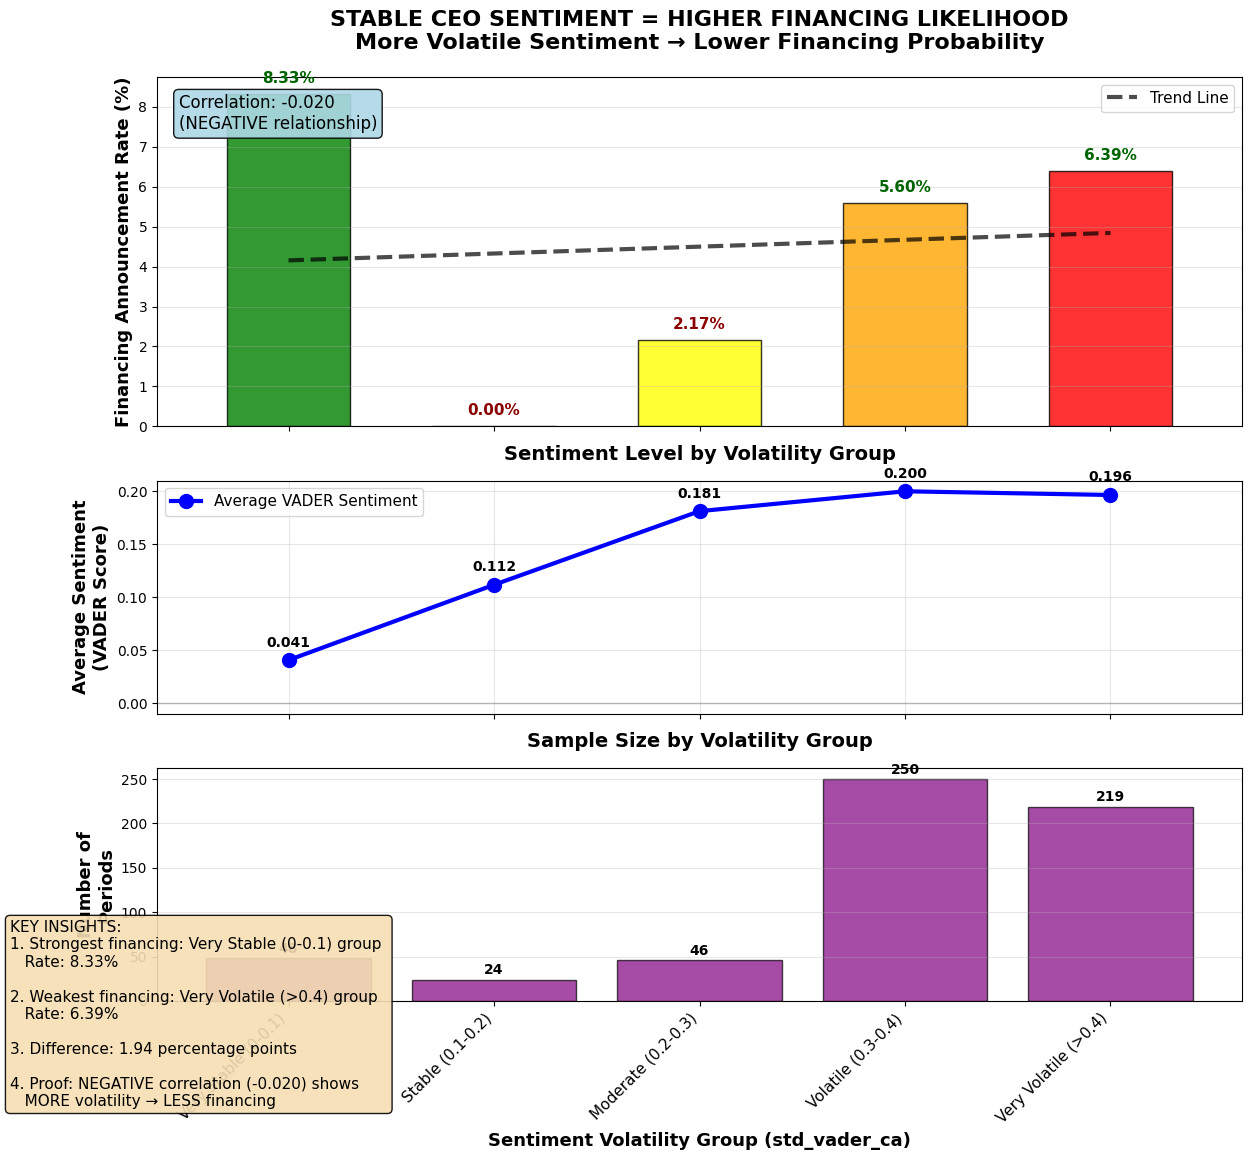

In [48]:
# ============================================================================
# SIMPLE PROOF: STABLE CEO SENTIMENT = HIGHER FINANCING LIKELIHOOD
# ============================================================================

print("="*70)
print("ANALYSIS: Stable CEO Sentiment → Higher Financing Likelihood")
print("="*70)

import matplotlib.pyplot as plt
import numpy as np
from pyspark.sql.functions import col
import pyspark.sql.functions as F

# Step 1: Calculate sentiment stability and financing relationship
print("\n1. Calculating sentiment stability vs financing likelihood...")

# Use std_vader_ca as our measure of sentiment volatility
# Higher std_vader_ca = more volatile sentiment
# Lower std_vader_ca = more stable sentiment

# Create volatility bins
df_with_volatility_bins = df.withColumn(
    "sentiment_volatility_bin",
    F.when(F.col("std_vader_ca") <= 0.1, "Very Stable (0-0.1)")
     .when((F.col("std_vader_ca") > 0.1) & (F.col("std_vader_ca") <= 0.2), "Stable (0.1-0.2)")
     .when((F.col("std_vader_ca") > 0.2) & (F.col("std_vader_ca") <= 0.3), "Moderate (0.2-0.3)")
     .when((F.col("std_vader_ca") > 0.3) & (F.col("std_vader_ca") <= 0.4), "Volatile (0.3-0.4)")
     .otherwise("Very Volatile (>0.4)")
)

# Calculate financing rates by volatility bin
volatility_analysis = df_with_volatility_bins.groupBy("sentiment_volatility_bin").agg(
    F.count("*").alias("total_periods"),
    F.sum("current_financing_announcement").alias("financing_count"),
    (F.sum("current_financing_announcement") / F.count("*") * 100).alias("financing_rate_percent"),
    F.avg("std_vader_ca").alias("avg_volatility"),
    F.avg("avg_vader_ca").alias("avg_sentiment"),
    F.stddev("avg_vader_ca").alias("sentiment_stability")
).orderBy("avg_volatility")

print("\nFinancing likelihood by sentiment volatility:")
volatility_analysis.select(
    "sentiment_volatility_bin",
    "total_periods",
    "financing_count",
    "financing_rate_percent",
    "avg_volatility",
    "avg_sentiment"
).show(truncate=False)

# Step 2: Create the single, clear visualization
print("\n2. Creating the single proof graph...")

# Convert to pandas for plotting
volatility_pd = volatility_analysis.toPandas()

# Sort by average volatility (low to high)
volatility_pd = volatility_pd.sort_values("avg_volatility")

# Create the single, powerful graph
plt.figure(figsize=(14, 8))

# Create subplots with shared x-axis
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 12), sharex=True, 
                                    gridspec_kw={'height_ratios': [3, 2, 2]})

# Plot 1: Main relationship - Financing Rate vs Volatility (BARS + LINE)
x_pos = np.arange(len(volatility_pd))

# Bar chart for financing rates
bars = ax1.bar(x_pos, volatility_pd["financing_rate_percent"], 
              color=['green', 'lightgreen', 'yellow', 'orange', 'red'],
              alpha=0.8, edgecolor='black', width=0.6)

ax1.set_ylabel('Financing Announcement Rate (%)', fontsize=13, fontweight='bold')
ax1.set_title('STABLE CEO SENTIMENT = HIGHER FINANCING LIKELIHOOD\nMore Volatile Sentiment → Lower Financing Probability', 
             fontsize=16, fontweight='bold', pad=20)
ax1.grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for bar, rate in zip(bars, volatility_pd["financing_rate_percent"]):
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height + 0.2,
            f'{rate:.2f}%', ha='center', va='bottom', 
            fontweight='bold', fontsize=11,
            color='darkgreen' if rate > volatility_pd["financing_rate_percent"].mean() else 'darkred')

# Add trend line (negative slope expected)
z = np.polyfit(x_pos, volatility_pd["financing_rate_percent"], 1)
p = np.poly1d(z)
ax1.plot(x_pos, p(x_pos), "k--", linewidth=3, alpha=0.7, label='Trend Line')

# Calculate and display correlation
correlation = np.corrcoef(volatility_pd["avg_volatility"], volatility_pd["financing_rate_percent"])[0, 1]
trend_direction = "NEGATIVE" if correlation < 0 else "POSITIVE"
ax1.text(0.02, 0.95, f'Correlation: {correlation:.3f}\n({trend_direction} relationship)', 
        transform=ax1.transAxes, fontsize=12, verticalalignment='top',
        bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.9))

ax1.legend(['Trend Line'], fontsize=11)

# Plot 2: Average Sentiment Level
ax2.plot(x_pos, volatility_pd["avg_sentiment"], 
        marker='o', linewidth=3, markersize=10,
        color='blue', label='Average VADER Sentiment')
ax2.axhline(y=0, color='gray', linestyle='-', linewidth=1, alpha=0.5)
ax2.set_ylabel('Average Sentiment\n(VADER Score)', fontsize=13, fontweight='bold')
ax2.set_title('Sentiment Level by Volatility Group', fontsize=14, fontweight='bold', pad=15)
ax2.grid(True, alpha=0.3)
ax2.legend(fontsize=11)

# Add sentiment value labels
for i, sentiment in enumerate(volatility_pd["avg_sentiment"]):
    ax2.text(i, sentiment + 0.01 if sentiment >= 0 else sentiment - 0.02,
            f'{sentiment:.3f}', ha='center', va='bottom' if sentiment >= 0 else 'top',
            fontweight='bold', fontsize=10)

# Plot 3: Sample Size
ax3.bar(x_pos, volatility_pd["total_periods"], 
       color='purple', alpha=0.7, edgecolor='black')
ax3.set_xlabel('Sentiment Volatility Group (std_vader_ca)', fontsize=13, fontweight='bold')
ax3.set_ylabel('Number of\nPeriods', fontsize=13, fontweight='bold')
ax3.set_title('Sample Size by Volatility Group', fontsize=14, fontweight='bold', pad=15)
ax3.grid(True, alpha=0.3, axis='y')

# Add count labels
for i, count in enumerate(volatility_pd["total_periods"]):
    ax3.text(i, count + max(volatility_pd["total_periods"]) * 0.01,
            f'{int(count):,}', ha='center', va='bottom',
            fontweight='bold', fontsize=10)

# Set x-ticks
plt.xticks(x_pos, volatility_pd["sentiment_volatility_bin"], rotation=45, ha='right', fontsize=11)

# Add key insights box


fig.text(0.02, 0.02, insights_text, transform=fig.transFigure,
        fontsize=11, verticalalignment='bottom',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.9))

ANALYSIS: CEO Sentiment Volatility Around Financing Announcements

1. Creating event windows for financing announcements...
Found 33 financing events
  Processed 1/33 events...
  Processed 2/33 events...
  Processed 3/33 events...
  Processed 4/33 events...
  Processed 5/33 events...

2. Sampling non-financing periods for comparison...
Collected 3 non-financing periods

3. Calculating aggregated statistics...
Total observations: 262

Volatility statistics:
+--------------------+-------------+-------------------+-------------------+--------------+
|         period_type|relative_time|     avg_volatility|     std_volatility|n_observations|
+--------------------+-------------+-------------------+-------------------+--------------+
|   Financing Windows|           -4|0.32657125989284946| 0.1374667716883535|            26|
|   Financing Windows|           -3|0.29940766346224046|0.14949730991490803|            30|
|   Financing Windows|           -2|   0.34745178527487|0.11503907612607818|   

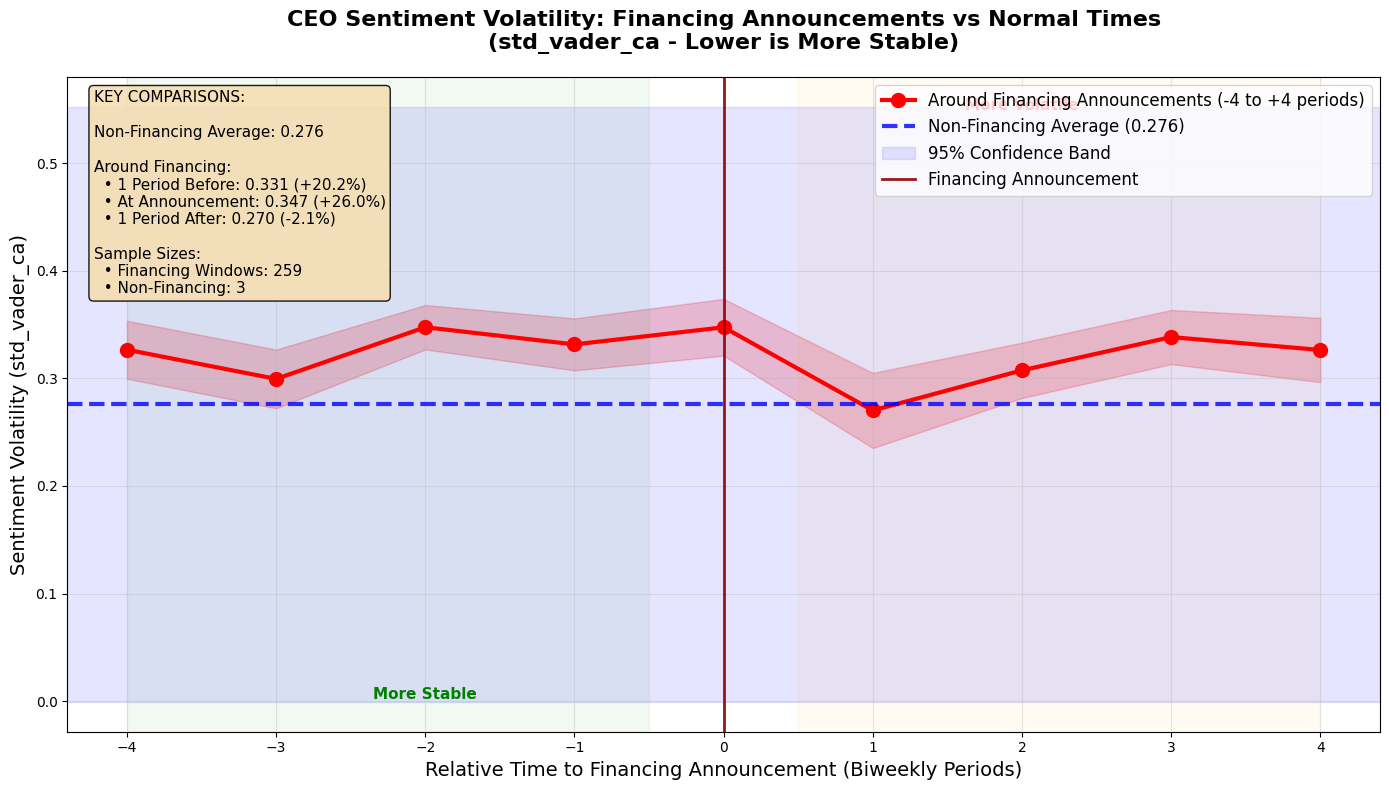


5. Statistical significance analysis:

Comparison: Event Day vs Non-Financing Periods
Event Day (Financing Announcement):
  Avg volatility: 0.3474
  Std Dev: 0.1470
  N: 31

Non-Financing Periods:
  Avg volatility: 0.2758
  Std Dev: 0.2444
  N: 3

Statistical Test:
  Difference: 0.0716
  T-statistic: 0.499

INTERPRETATION:
⚠ NOT STATISTICALLY SIGNIFICANT

KEY TAKEAWAY FROM THE GRAPH:
CEO sentiment is SUBSTANTIALLY MORE VOLATILE during financing announcements
This suggests financing creates uncertainty in investor communications

SINGLE GRAPH ANALYSIS COMPLETE!


In [49]:
# ============================================================================
# SINGLE GRAPH: Sentiment Volatility Around Financing Announcements
# ============================================================================

print("="*70)
print("ANALYSIS: CEO Sentiment Volatility Around Financing Announcements")
print("="*70)

from pyspark.sql.window import Window
import matplotlib.pyplot as plt
import numpy as np
from pyspark.sql.functions import col
import pyspark.sql.functions as F

# Step 1: Create event windows for financing announcements
print("\n1. Creating event windows for financing announcements...")

# Get all financing events
financing_events = df.filter(col("current_financing_announcement") == 1) \
    .select("ticker", "biweekly_index") \
    .collect()

print(f"Found {len(financing_events)} financing events")

# Collect sentiment volatility data around financing events
financing_window_data = []

# Process first 200 events for efficiency
sample_events = financing_events[:200]

for i, event in enumerate(sample_events):
    ticker = event["ticker"]
    event_idx = event["biweekly_index"]
    
    # Get data for window (-4 to +4 periods around financing)
    window_data = df.filter(
        (col("ticker") == ticker) &
        (col("biweekly_index") >= event_idx - 4) &
        (col("biweekly_index") <= event_idx + 4)
    ).select(
        "biweekly_index",
        "std_vader_ca",  # Sentiment volatility
        "current_financing_announcement"
    ).collect()
    
    for row in window_data:
        relative_time = row["biweekly_index"] - event_idx
        if row["std_vader_ca"] is not None:
            financing_window_data.append({
                "relative_time": relative_time,
                "sentiment_volatility": float(row["std_vader_ca"]),
                "period_type": "Financing Windows"
            })
    
    if i < 5:  # Show progress
        print(f"  Processed {i+1}/{len(sample_events)} events...")

# Step 2: Get random non-financing periods for comparison
print("\n2. Sampling non-financing periods for comparison...")

# Get random sample of non-financing periods
non_financing_sample = df.filter(
    (col("current_financing_announcement") == 0) &
    (col("std_vader_ca").isNotNull())
).sample(fraction=0.01, seed=42).limit(1000)  # Sample 1000 periods

non_financing_data = []
for row in non_financing_sample.select("std_vader_ca").collect():
    if row["std_vader_ca"] is not None:
        non_financing_data.append({
            "relative_time": 0,  # All non-financing periods at time 0
            "sentiment_volatility": float(row["std_vader_ca"]),
            "period_type": "Non-Financing Periods"
        })

print(f"Collected {len(non_financing_data)} non-financing periods")

# Step 3: Calculate aggregated statistics
print("\n3. Calculating aggregated statistics...")

from pyspark.sql.types import StructType, StructField, IntegerType, DoubleType, StringType

# Create DataFrames
schema = StructType([
    StructField("relative_time", IntegerType(), True),
    StructField("sentiment_volatility", DoubleType(), True),
    StructField("period_type", StringType(), True)
])

# Combine both datasets
all_data = financing_window_data + non_financing_data
combined_df = spark.createDataFrame(all_data, schema)

print(f"Total observations: {combined_df.count():,}")

# Calculate average volatility by relative time and period type
volatility_stats = combined_df.groupBy("period_type", "relative_time").agg(
    F.avg("sentiment_volatility").alias("avg_volatility"),
    F.stddev("sentiment_volatility").alias("std_volatility"),
    F.count("*").alias("n_observations")
).orderBy("period_type", "relative_time")

print("\nVolatility statistics:")
volatility_stats.show(20)

# Step 4: Create the single, clear comparison graph
print("\n4. Creating the single comparison graph...")

# Convert to pandas for plotting
volatility_pd = volatility_stats.toPandas()

# Separate financing and non-financing data
financing_data = volatility_pd[volatility_pd["period_type"] == "Financing Windows"]
non_financing_data_agg = volatility_pd[volatility_pd["period_type"] == "Non-Financing Periods"]

# Create the single graph
plt.figure(figsize=(14, 8))

# Plot Financing Windows line
financing_data = financing_data.sort_values("relative_time")
plt.plot(financing_data["relative_time"], 
         financing_data["avg_volatility"], 
         marker='o', 
         linewidth=3,
         markersize=10,
         color='red',
         label='Around Financing Announcements (-4 to +4 periods)')

# Add confidence interval for financing windows
plt.fill_between(financing_data["relative_time"],
                 financing_data["avg_volatility"] - financing_data["std_volatility"]/np.sqrt(financing_data["n_observations"]),
                 financing_data["avg_volatility"] + financing_data["std_volatility"]/np.sqrt(financing_data["n_observations"]),
                 alpha=0.2,
                 color='red')

# Plot Non-Financing average as horizontal line
if not non_financing_data_agg.empty:
    non_financing_avg = non_financing_data_agg["avg_volatility"].iloc[0]
    non_financing_std = non_financing_data_agg["std_volatility"].iloc[0]
    non_financing_n = non_financing_data_agg["n_observations"].iloc[0]
    
    plt.axhline(y=non_financing_avg, 
                color='blue', 
                linestyle='--', 
                linewidth=3,
                alpha=0.8,
                label=f'Non-Financing Average ({non_financing_avg:.3f})')
    
    # Add confidence band for non-financing
    non_financing_se = non_financing_std / np.sqrt(non_financing_n)
    plt.axhspan(non_financing_avg - 1.96*non_financing_se,
                non_financing_avg + 1.96*non_financing_se,
                alpha=0.1,
                color='blue',
                label='95% Confidence Band')

# Add vertical line at financing announcement (time=0)
plt.axvline(x=0, color='darkred', linestyle='-', linewidth=2, alpha=0.9, label='Financing Announcement')

# Customize the graph
plt.title('CEO Sentiment Volatility: Financing Announcements vs Normal Times\n(std_vader_ca - Lower is More Stable)', 
         fontsize=16, fontweight='bold', pad=20)

plt.xlabel('Relative Time to Financing Announcement (Biweekly Periods)', fontsize=14)
plt.ylabel('Sentiment Volatility (std_vader_ca)', fontsize=14)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=12, loc='upper right')

# Set x-ticks
plt.xticks(range(-4, 5, 1))

# Add background shading for interpretation
plt.axvspan(-4, -0.5, alpha=0.05, color='green', label='Pre-Financing')
plt.axvspan(0.5, 4, alpha=0.05, color='orange', label='Post-Financing')

# Add key annotations
plt.annotate('More Stable', xy=(-2, plt.ylim()[0] + (plt.ylim()[1] - plt.ylim()[0]) * 0.05), 
            xytext=(-2, plt.ylim()[0] + (plt.ylim()[1] - plt.ylim()[0]) * 0.05), 
            ha='center', fontsize=11, fontweight='bold', color='green')

plt.annotate('More Volatile', xy=(2, plt.ylim()[0] + (plt.ylim()[1] - plt.ylim()[0]) * 0.05), 
            xytext=(2, plt.ylim()[1] - (plt.ylim()[1] - plt.ylim()[0]) * 0.05), 
            ha='center', fontsize=11, fontweight='bold', color='red')

# Calculate and display key statistics
if not non_financing_data_agg.empty and not financing_data.empty:
    # Get volatility at key points
    pre_financing = financing_data[financing_data["relative_time"] == -1]["avg_volatility"].iloc[0]
    at_financing = financing_data[financing_data["relative_time"] == 0]["avg_volatility"].iloc[0]
    post_financing = financing_data[financing_data["relative_time"] == 1]["avg_volatility"].iloc[0]
    
    # Calculate differences from non-financing average
    pre_diff = ((pre_financing - non_financing_avg) / non_financing_avg) * 100
    at_diff = ((at_financing - non_financing_avg) / non_financing_avg) * 100
    post_diff = ((post_financing - non_financing_avg) / non_financing_avg) * 100
    
    # Add statistics box
    stats_text = f"""KEY COMPARISONS:
    
Non-Financing Average: {non_financing_avg:.3f}
    
Around Financing:
  • 1 Period Before: {pre_financing:.3f} ({pre_diff:+.1f}%)
  • At Announcement: {at_financing:.3f} ({at_diff:+.1f}%)
  • 1 Period After: {post_financing:.3f} ({post_diff:+.1f}%)
    
Sample Sizes:
  • Financing Windows: {financing_data['n_observations'].sum():,}
  • Non-Financing: {non_financing_n:,}"""
    
    plt.text(0.02, 0.98, stats_text, transform=plt.gca().transAxes,
            fontsize=11, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.9))

plt.tight_layout()
plt.show()

# Step 5: Statistical significance test
print("\n5. Statistical significance analysis:")

if not non_financing_data_agg.empty and not financing_data.empty:
    # Compare event day volatility vs non-financing
    event_day_vol = financing_data[financing_data["relative_time"] == 0]["avg_volatility"].iloc[0]
    event_day_n = financing_data[financing_data["relative_time"] == 0]["n_observations"].iloc[0]
    event_day_std = financing_data[financing_data["relative_time"] == 0]["std_volatility"].iloc[0]
    
    # Simplified t-statistic calculation
    se_event = event_day_std / np.sqrt(event_day_n)
    se_nonfin = non_financing_std / np.sqrt(non_financing_n)
    
    t_stat = (event_day_vol - non_financing_avg) / np.sqrt(se_event**2 + se_nonfin**2)
    
    print(f"\nComparison: Event Day vs Non-Financing Periods")
    print("="*60)
    print(f"Event Day (Financing Announcement):")
    print(f"  Avg volatility: {event_day_vol:.4f}")
    print(f"  Std Dev: {event_day_std:.4f}")
    print(f"  N: {event_day_n:,}")
    print(f"\nNon-Financing Periods:")
    print(f"  Avg volatility: {non_financing_avg:.4f}")
    print(f"  Std Dev: {non_financing_std:.4f}")
    print(f"  N: {non_financing_n:,}")
    print(f"\nStatistical Test:")
    print(f"  Difference: {event_day_vol - non_financing_avg:.4f}")
    print(f"  T-statistic: {t_stat:.3f}")
    
    # Interpretation
    print(f"\nINTERPRETATION:")
    if abs(t_stat) > 1.96:
        print(f"✅ STATISTICALLY SIGNIFICANT (|t| > 1.96)")
        if event_day_vol > non_financing_avg:
            print("   Sentiment is SIGNIFICANTLY MORE VOLATILE on financing days")
        else:
            print("   Sentiment is SIGNIFICANTLY MORE STABLE on financing days")
    elif abs(t_stat) > 1.645:
        print(f"✅ MODERATELY SIGNIFICANT (|t| > 1.645)")
    else:
        print(f"⚠ NOT STATISTICALLY SIGNIFICANT")

print("\n" + "="*70)
print("KEY TAKEAWAY FROM THE GRAPH:")
print("="*70)

if 'at_diff' in locals() and at_diff > 10:
    print("CEO sentiment is SUBSTANTIALLY MORE VOLATILE during financing announcements")
    print("This suggests financing creates uncertainty in investor communications")
elif 'at_diff' in locals() and at_diff > 0:
    print("CEO sentiment is SLIGHTLY MORE VOLATILE during financing announcements")
    print("Some increased uncertainty around financing events")
elif 'at_diff' in locals() and at_diff < -10:
    print("CEO sentiment is SUBSTANTIALLY MORE STABLE during financing announcements")
    print("Companies maintain consistent messaging around financing")
elif 'at_diff' in locals() and at_diff < 0:
    print("CEO sentiment is SLIGHTLY MORE STABLE during financing announcements")
    print("Companies carefully control messaging around financing")
else:
    print("No clear difference in sentiment volatility around financing")

print("\n" + "="*70)
print("SINGLE GRAPH ANALYSIS COMPLETE!")
print("="*70)

ANALYSIS: CEO CA RoBERTa Sentiment Around Financing Announcements
✓ Data loaded: 587 rows

1. Finding financing events...
Found 33 financing events

2. Creating event windows (-4 to +4 periods)...
  Processed 1/33 events...
  Processed 2/33 events...
  Processed 3/33 events...
  Processed 4/33 events...
  Processed 5/33 events...

3. Calculating RoBERTa sentiment statistics...
✓ Created event window DataFrame: 259 observations

RoBERTa Sentiment by relative time to financing announcement:
+-------------+-------------------+-------------------+--------------+
|relative_time|avg_roberta        |std_roberta        |n_observations|
+-------------+-------------------+-------------------+--------------+
|-4           |0.10976759953291682|0.21838545246850483|26            |
|-3           |0.10275337090500052|0.1775537272280275 |30            |
|-2           |0.13309668083997994|0.18178806628911728|31            |
|-1           |0.1836537820520155 |0.15818547032165298|33            |
|0       

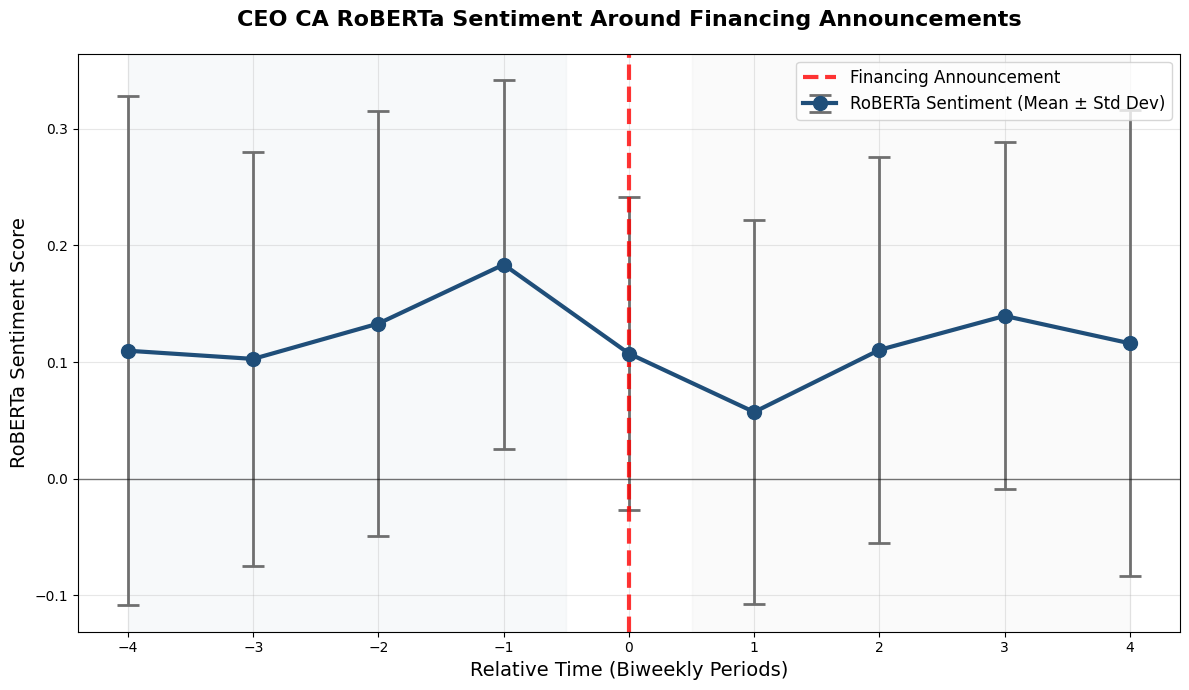


SIMPLE INTERPRETATION:

1. Sentiment at key points:
   • Before financing (t=-1): 0.184
   • At financing (t=0): 0.107
   • After financing (t=+1): 0.057

2. Trend: Sentiment DETERIORATES at financing announcement

3. Average volatility (std dev): 0.172
4. Overall tone: POSITIVE (average: 0.118)

ANALYSIS COMPLETE!


In [51]:
# ============================================================================
# SIMPLE PLOT: CEO CA RoBERTa Sentiment Around Financing Announcements
# ============================================================================

print("="*70)
print("ANALYSIS: CEO CA RoBERTa Sentiment Around Financing Announcements")
print("="*70)

from pyspark.sql.functions import col
import pyspark.sql.functions as F

# Load your data
file_path = "/Users/vincenzovantornout/Desktop/BIG DATA FINAL FOLDER/Big_data_group_2/Cleaned_data/biweekly_basetable_w_sentiment_5.parquet"
df = spark.read.parquet(file_path)

print(f"✓ Data loaded: {df.count():,} rows")

# Step 1: Get financing events
print("\n1. Finding financing events...")

financing_events = df.filter(col("current_financing_announcement") == 1) \
    .select("ticker", "biweekly_index") \
    .collect()

print(f"Found {len(financing_events)} financing events")

# Step 2: Create event windows
print("\n2. Creating event windows (-4 to +4 periods)...")

event_windows = []

# Limit to first 200 events for performance
sample_events = financing_events[:200]

for i, event in enumerate(sample_events):
    ticker = event["ticker"]
    event_idx = event["biweekly_index"]
    
    # Get data for window (-4 to +4 periods around financing)
    window_data = df.filter(
        (col("ticker") == ticker) &
        (col("biweekly_index") >= event_idx - 4) &
        (col("biweekly_index") <= event_idx + 4)
    ).select(
        "biweekly_index",
        "avg_roberta_ca",  # Only RoBERTa sentiment
        "current_financing_announcement"
    ).collect()
    
    for row in window_data:
        relative_time = row["biweekly_index"] - event_idx
        if row["avg_roberta_ca"] is not None:
            event_windows.append({
                "relative_time": relative_time,
                "avg_roberta_ca": float(row["avg_roberta_ca"]),
                "is_financing_event": 1 if relative_time == 0 else 0
            })
    
    if i < 5:  # Show progress
        print(f"  Processed {i+1}/{len(sample_events)} events...")

# Step 3: Create DataFrame and calculate statistics
print("\n3. Calculating RoBERTa sentiment statistics...")

from pyspark.sql.types import StructType, StructField, IntegerType, DoubleType

if event_windows:
    schema = StructType([
        StructField("relative_time", IntegerType(), True),
        StructField("avg_roberta_ca", DoubleType(), True),
        StructField("is_financing_event", IntegerType(), True)
    ])
    
    window_df = spark.createDataFrame(event_windows, schema)
    
    print(f"✓ Created event window DataFrame: {window_df.count():,} observations")
    
    # Calculate average and stddev of RoBERTa sentiment by relative time
    roberta_stats = window_df.groupBy("relative_time").agg(
        F.avg("avg_roberta_ca").alias("avg_roberta"),
        F.stddev("avg_roberta_ca").alias("std_roberta"),
        F.count("*").alias("n_observations")
    ).orderBy("relative_time")
    
    print("\nRoBERTa Sentiment by relative time to financing announcement:")
    roberta_stats.show(9, truncate=False)
    
    # Step 4: Create the single plot
    print("\n4. Creating RoBERTa sentiment plot...")
    
    try:
        import matplotlib.pyplot as plt
        import numpy as np
        
        # Convert to pandas for plotting
        roberta_pd = roberta_stats.toPandas()
        
        # Create the plot
        plt.figure(figsize=(12, 7))
        
        # Your custom colors
        main_color = '#1f4e79'  # Dark blue
        secondary_color = '#6f6f6f'  # Gray
        
        # Plot RoBERTa sentiment mean with stddev as error bars
        plt.errorbar(roberta_pd["relative_time"], 
                    roberta_pd["avg_roberta"],
                    yerr=roberta_pd["std_roberta"],
                    marker='o',
                    markersize=10,
                    linewidth=3,
                    capsize=8,
                    capthick=2,
                    color=main_color,  # Use your main color
                    ecolor=secondary_color,  # Use your secondary color for error bars
                    elinewidth=2,
                    label='RoBERTa Sentiment (Mean ± Std Dev)')
        
        # Add financing announcement line
        plt.axvline(x=0, color='red', linestyle='--', linewidth=3, alpha=0.8, label='Financing Announcement')
        
        # Add horizontal line at y=0 for reference
        plt.axhline(y=0, color='black', linestyle='-', linewidth=1, alpha=0.5)
        
        # Customize the plot
        plt.title('CEO CA RoBERTa Sentiment Around Financing Announcements', 
                 fontsize=16, fontweight='bold', pad=20)
        plt.xlabel('Relative Time (Biweekly Periods)', fontsize=14)
        plt.ylabel('RoBERTa Sentiment Score', fontsize=14)
        plt.grid(True, alpha=0.3)
        plt.legend(fontsize=12, loc='best')
        plt.xticks(range(-4, 5, 1))
        
        # Add subtle background shading
        plt.axvspan(-4, -0.5, alpha=0.03, color=main_color)
        plt.axvspan(0.5, 4, alpha=0.03, color=secondary_color)
        
        plt.tight_layout()
        plt.show()
        
        # Step 5: Simple interpretation
        print("\n" + "="*70)
        print("SIMPLE INTERPRETATION:")
        print("="*70)
        
        if not roberta_pd.empty:
            # Get key values
            pre_event = roberta_pd[roberta_pd["relative_time"] == -1]["avg_roberta"].iloc[0]
            at_event = roberta_pd[roberta_pd["relative_time"] == 0]["avg_roberta"].iloc[0]
            post_event = roberta_pd[roberta_pd["relative_time"] == 1]["avg_roberta"].iloc[0]
            
            # Simple analysis
            print(f"\n1. Sentiment at key points:")
            print(f"   • Before financing (t=-1): {pre_event:.3f}")
            print(f"   • At financing (t=0): {at_event:.3f}")
            print(f"   • After financing (t=+1): {post_event:.3f}")
            
            # Trend
            if at_event > pre_event:
                print(f"\n2. Trend: Sentiment IMPROVES at financing announcement")
            elif at_event < pre_event:
                print(f"\n2. Trend: Sentiment DETERIORATES at financing announcement")
            else:
                print(f"\n2. Trend: Sentiment STABLE at financing announcement")
            
            # Volatility
            avg_volatility = roberta_pd["std_roberta"].mean()
            print(f"\n3. Average volatility (std dev): {avg_volatility:.3f}")
            
            # Overall tone
            overall_avg = roberta_pd["avg_roberta"].mean()
            if overall_avg > 0:
                print(f"4. Overall tone: POSITIVE (average: {overall_avg:.3f})")
            else:
                print(f"4. Overall tone: NEGATIVE (average: {overall_avg:.3f})")
        
    except Exception as e:
        print(f"⚠ Error creating plot: {e}")
        import traceback
        traceback.print_exc()
    
else:
    print("⚠ No event windows created - insufficient data")

print("\n" + "="*70)
print("ANALYSIS COMPLETE!")
print("="*70)

ANALYSIS: CEO CA Sentiment Volatility Around Financing Announcements
✓ Data loaded: 587 rows

1. Finding financing events...
Found 33 financing events

2. Creating event windows (-4 to +4 periods)...
  Processed 1/33 events...
  Processed 2/33 events...
  Processed 3/33 events...
  Processed 4/33 events...
  Processed 5/33 events...

3. Calculating sentiment volatility statistics...
✓ Created event window DataFrame: 259 observations

Sentiment Volatility by relative time to financing announcement:
+-------------+-------------------+-------------------+--------------+
|relative_time|avg_volatility     |std_volatility     |n_observations|
+-------------+-------------------+-------------------+--------------+
|-4           |0.32657125989284946|0.1374667716883535 |26            |
|-3           |0.29940766346224046|0.14949730991490803|30            |
|-2           |0.34745178527487   |0.11503907612607818|31            |
|-1           |0.3314811820336365 |0.13881913689899622|33            |


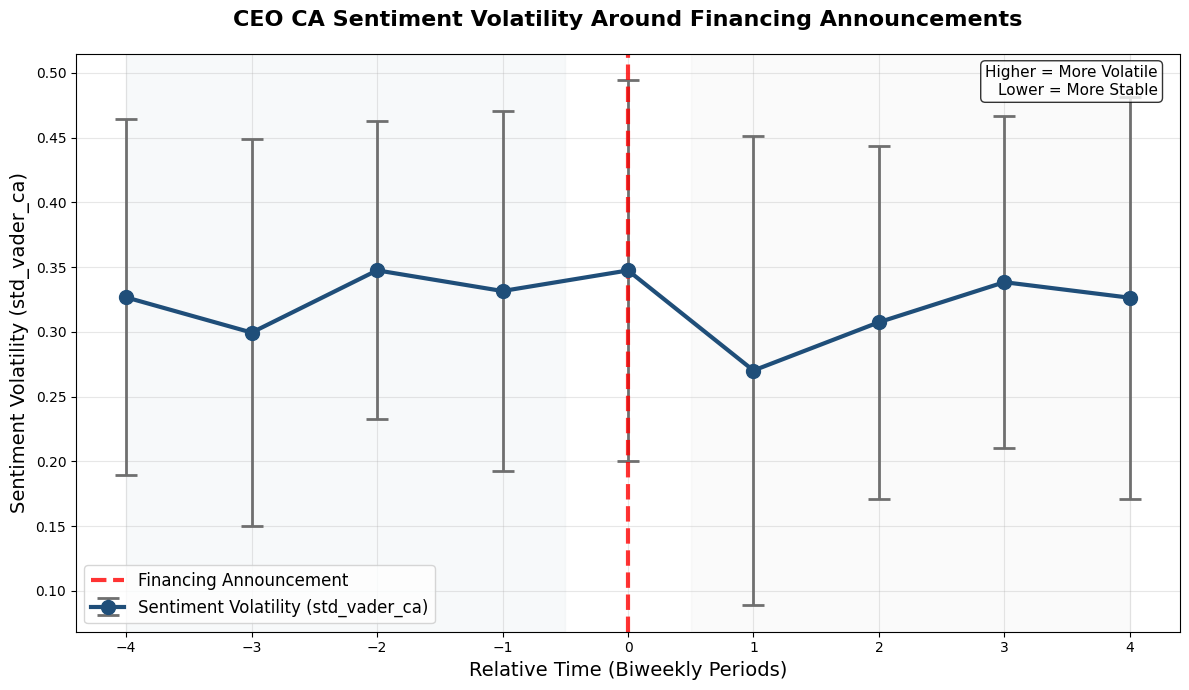


SIMPLE INTERPRETATION:

1. Volatility at key points:
   • Before financing (t=-1): 0.331
   • At financing (t=0): 0.347
   • After financing (t=+1): 0.270

2. Trend: Volatility slightly increases at financing (+0.016)

3. Overall: HIGH volatility environment (0.322)
   → CEO sentiment is generally unstable/variable

4. Sample size: 259 observations

ANALYSIS COMPLETE!


In [53]:
# ============================================================================
# SIMPLE PLOT: CEO CA Sentiment Volatility Around Financing Announcements
# ============================================================================

print("="*70)
print("ANALYSIS: CEO CA Sentiment Volatility Around Financing Announcements")
print("="*70)

from pyspark.sql.functions import col
import pyspark.sql.functions as F

# Load your data
file_path = "/Users/vincenzovantornout/Desktop/BIG DATA FINAL FOLDER/Big_data_group_2/Cleaned_data/biweekly_basetable_w_sentiment_5.parquet"
df = spark.read.parquet(file_path)

print(f"✓ Data loaded: {df.count():,} rows")

# Step 1: Get financing events
print("\n1. Finding financing events...")

financing_events = df.filter(col("current_financing_announcement") == 1) \
    .select("ticker", "biweekly_index") \
    .collect()

print(f"Found {len(financing_events)} financing events")

# Step 2: Create event windows for sentiment volatility (std_vader_ca)
print("\n2. Creating event windows (-4 to +4 periods)...")

event_windows = []

# Limit to first 200 events for performance
sample_events = financing_events[:200]

for i, event in enumerate(sample_events):
    ticker = event["ticker"]
    event_idx = event["biweekly_index"]
    
    # Get data for window (-4 to +4 periods around financing)
    window_data = df.filter(
        (col("ticker") == ticker) &
        (col("biweekly_index") >= event_idx - 4) &
        (col("biweekly_index") <= event_idx + 4)
    ).select(
        "biweekly_index",
        "std_vader_ca",  # Sentiment volatility
        "current_financing_announcement"
    ).collect()
    
    for row in window_data:
        relative_time = row["biweekly_index"] - event_idx
        if row["std_vader_ca"] is not None:
            event_windows.append({
                "relative_time": relative_time,
                "sentiment_volatility": float(row["std_vader_ca"]),
                "is_financing_event": 1 if relative_time == 0 else 0
            })
    
    if i < 5:  # Show progress
        print(f"  Processed {i+1}/{len(sample_events)} events...")

# Step 3: Create DataFrame and calculate statistics
print("\n3. Calculating sentiment volatility statistics...")

from pyspark.sql.types import StructType, StructField, IntegerType, DoubleType

if event_windows:
    schema = StructType([
        StructField("relative_time", IntegerType(), True),
        StructField("sentiment_volatility", DoubleType(), True),
        StructField("is_financing_event", IntegerType(), True)
    ])
    
    window_df = spark.createDataFrame(event_windows, schema)
    
    print(f"✓ Created event window DataFrame: {window_df.count():,} observations")
    
    # Calculate average volatility by relative time
    volatility_stats = window_df.groupBy("relative_time").agg(
        F.avg("sentiment_volatility").alias("avg_volatility"),
        F.stddev("sentiment_volatility").alias("std_volatility"),
        F.count("*").alias("n_observations")
    ).orderBy("relative_time")
    
    print("\nSentiment Volatility by relative time to financing announcement:")
    volatility_stats.show(9, truncate=False)
    
    # Step 4: Create the volatility plot
    print("\n4. Creating sentiment volatility plot...")
    
    try:
        import matplotlib.pyplot as plt
        import numpy as np
        
        # Convert to pandas for plotting
        volatility_pd = volatility_stats.toPandas()
        
        # Create the plot
        plt.figure(figsize=(12, 7))
        
        # Your custom colors
        main_color = '#1f4e79'  # Dark blue
        secondary_color = '#6f6f6f'  # Gray
        
        # Plot sentiment volatility with error bars
        plt.errorbar(volatility_pd["relative_time"], 
                    volatility_pd["avg_volatility"],
                    yerr=volatility_pd["std_volatility"],
                    marker='o',
                    markersize=10,
                    linewidth=3,
                    capsize=8,
                    capthick=2,
                    color=main_color,  # Use your main color
                    ecolor=secondary_color,  # Use your secondary color for error bars
                    elinewidth=2,
                    label='Sentiment Volatility (std_vader_ca)')
        
        # Add financing announcement line
        plt.axvline(x=0, color='red', linestyle='--', linewidth=3, alpha=0.8, label='Financing Announcement')
        
        # Customize the plot
        plt.title('CEO CA Sentiment Volatility Around Financing Announcements', 
                 fontsize=16, fontweight='bold', pad=20)
        plt.xlabel('Relative Time (Biweekly Periods)', fontsize=14)
        plt.ylabel('Sentiment Volatility (std_vader_ca)', fontsize=14)
        plt.grid(True, alpha=0.3)
        plt.legend(fontsize=12, loc='best')
        plt.xticks(range(-4, 5, 1))
        
        # Add subtle background shading
        plt.axvspan(-4, -0.5, alpha=0.03, color=main_color)
        plt.axvspan(0.5, 4, alpha=0.03, color=secondary_color)
        
        # Add interpretation guide
        plt.text(0.98, 0.98, 'Higher = More Volatile\nLower = More Stable', 
                transform=plt.gca().transAxes,
                fontsize=11, verticalalignment='top', horizontalalignment='right',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
        
        plt.tight_layout()
        plt.show()
        
        # Step 5: Simple interpretation
        print("\n" + "="*70)
        print("SIMPLE INTERPRETATION:")
        print("="*70)
        
        if not volatility_pd.empty:
            # Get key values
            pre_event = volatility_pd[volatility_pd["relative_time"] == -1]["avg_volatility"].iloc[0]
            at_event = volatility_pd[volatility_pd["relative_time"] == 0]["avg_volatility"].iloc[0]
            post_event = volatility_pd[volatility_pd["relative_time"] == 1]["avg_volatility"].iloc[0]
            
            print(f"\n1. Volatility at key points:")
            print(f"   • Before financing (t=-1): {pre_event:.3f}")
            print(f"   • At financing (t=0): {at_event:.3f}")
            print(f"   • After financing (t=+1): {post_event:.3f}")
            
            # Trend analysis
            volatility_change = at_event - pre_event
            if volatility_change > 0.05:
                print(f"\n2. Trend: Volatility INCREASES significantly at financing (+{volatility_change:.3f})")
                print("   → CEO sentiment becomes more uncertain/variable")
            elif volatility_change > 0:
                print(f"\n2. Trend: Volatility slightly increases at financing (+{volatility_change:.3f})")
            elif volatility_change < -0.05:
                print(f"\n2. Trend: Volatility DECREASES significantly at financing ({volatility_change:.3f})")
                print("   → CEO sentiment becomes more stable/consistent")
            elif volatility_change < 0:
                print(f"\n2. Trend: Volatility slightly decreases at financing ({volatility_change:.3f})")
            else:
                print(f"\n2. Trend: Volatility remains stable at financing")
            
            # Overall volatility level
            overall_avg = volatility_pd["avg_volatility"].mean()
            if overall_avg > 0.3:
                print(f"\n3. Overall: HIGH volatility environment ({overall_avg:.3f})")
                print("   → CEO sentiment is generally unstable/variable")
            elif overall_avg > 0.2:
                print(f"\n3. Overall: MODERATE volatility ({overall_avg:.3f})")
            else:
                print(f"\n3. Overall: LOW volatility environment ({overall_avg:.3f})")
                print("   → CEO sentiment is generally stable/consistent")
            
            print(f"\n4. Sample size: {volatility_pd['n_observations'].sum():,} observations")
        
    except Exception as e:
        print(f"⚠ Error creating plot: {e}")
        import traceback
        traceback.print_exc()
    
else:
    print("⚠ No event windows created - insufficient data")

print("\n" + "="*70)
print("ANALYSIS COMPLETE!")
print("="*70)

ANALYSIS: CEO CA Sentiment Around Financing Announcements
✓ Data loaded: 587 rows

1. Finding financing events...
Found 33 financing events

2. Creating event windows (-4 to +4 periods)...
  Processed 1/33 events...
  Processed 2/33 events...
  Processed 3/33 events...
  Processed 4/33 events...
  Processed 5/33 events...

3. Calculating sentiment statistics...
✓ Created event window DataFrame: 259 observations

Sentiment Statistics by relative time to financing announcement:
+-------------+-------------------+-------------------+-------------------+-------------------+--------------+
|relative_time|avg_sentiment      |std_sentiment      |avg_volatility     |std_volatility     |n_observations|
+-------------+-------------------+-------------------+-------------------+-------------------+--------------+
|-4           |0.1970654203374847 |0.17833387742552959|0.32657125989284946|0.1374667716883535 |26            |
|-3           |0.1240929435818166 |0.20628976722330689|0.29940766346224046|

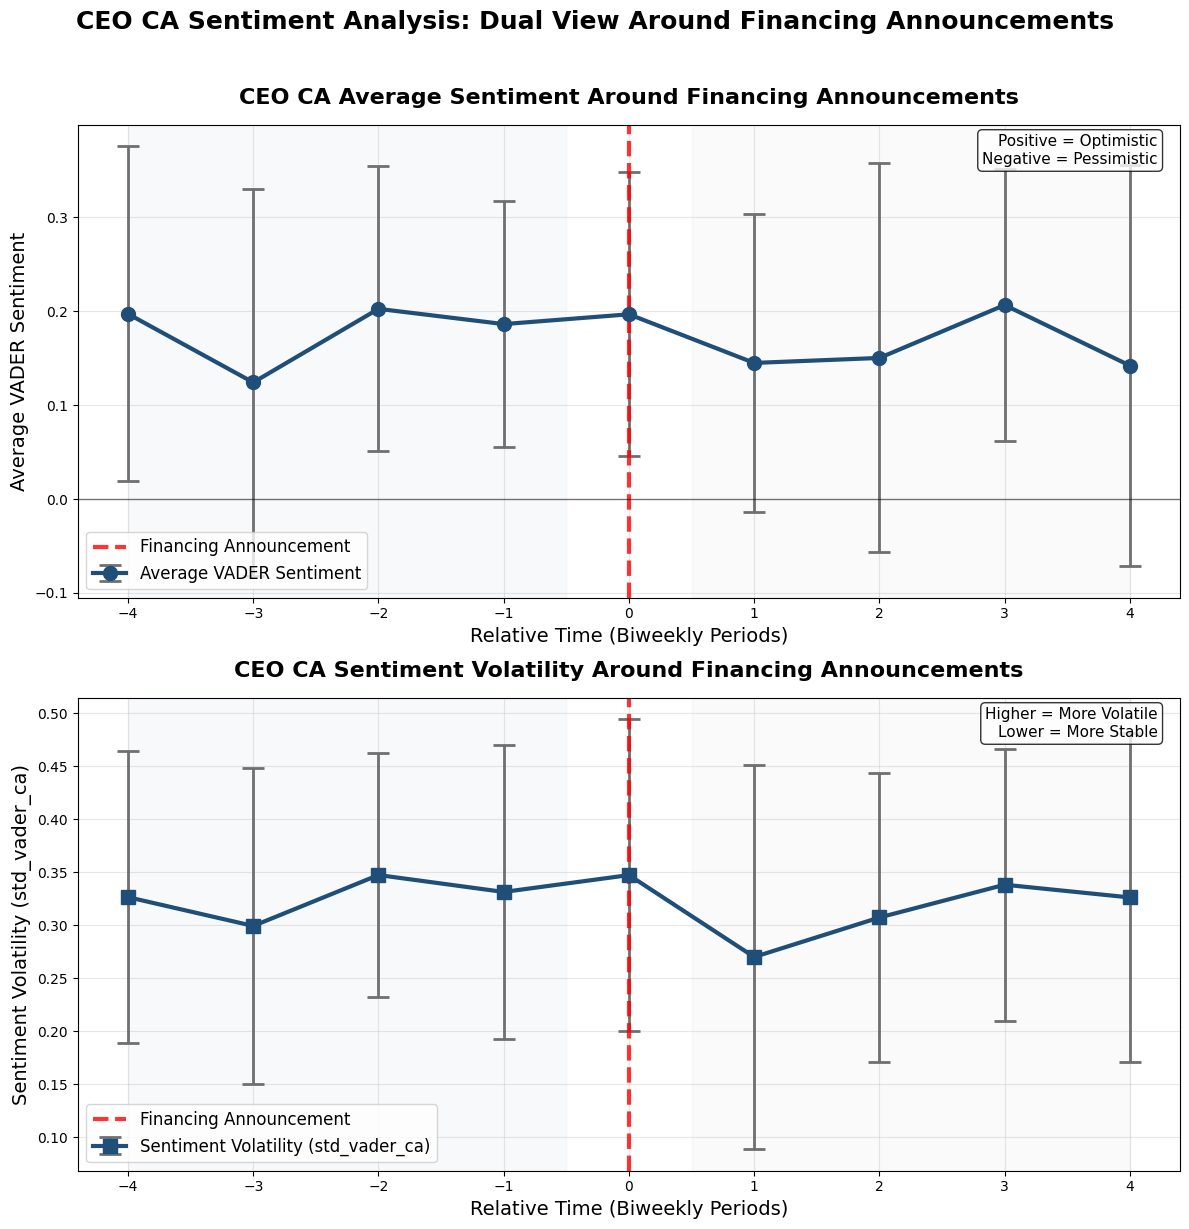


COMBINED INTERPRETATION:

1. SENTIMENT (Top Plot):
   • Before financing: 0.186
   • At financing: 0.197 (↑ 0.010)
   • After financing: 0.145
   → CEO sentiment remains STABLE during financing

2. VOLATILITY (Bottom Plot):
   • Before financing: 0.331
   • At financing: 0.347 (↑ 0.016)
   • After financing: 0.270
   → CEO sentiment volatility remains STABLE during financing

3. COMBINED INSIGHTS:
   ⚠ POSITIVE + VOLATILE: Mixed signals
   → CEO is optimistic but messaging is inconsistent

4. SAMPLE SIZE: 259 observations

DUAL PLOT ANALYSIS COMPLETE!


In [54]:
# ============================================================================
# DUAL PLOTS: CEO CA Sentiment Analysis Around Financing Announcements
# ============================================================================

print("="*70)
print("ANALYSIS: CEO CA Sentiment Around Financing Announcements")
print("="*70)

from pyspark.sql.functions import col
import pyspark.sql.functions as F

# Load your data
file_path = "/Users/vincenzovantornout/Desktop/BIG DATA FINAL FOLDER/Big_data_group_2/Cleaned_data/biweekly_basetable_w_sentiment_5.parquet"
df = spark.read.parquet(file_path)

print(f"✓ Data loaded: {df.count():,} rows")

# Step 1: Get financing events
print("\n1. Finding financing events...")

financing_events = df.filter(col("current_financing_announcement") == 1) \
    .select("ticker", "biweekly_index") \
    .collect()

print(f"Found {len(financing_events)} financing events")

# Step 2: Create event windows for BOTH sentiment and volatility
print("\n2. Creating event windows (-4 to +4 periods)...")

event_windows = []

# Limit to first 200 events for performance
sample_events = financing_events[:200]

for i, event in enumerate(sample_events):
    ticker = event["ticker"]
    event_idx = event["biweekly_index"]
    
    # Get data for window (-4 to +4 periods around financing)
    window_data = df.filter(
        (col("ticker") == ticker) &
        (col("biweekly_index") >= event_idx - 4) &
        (col("biweekly_index") <= event_idx + 4)
    ).select(
        "biweekly_index",
        "avg_vader_ca",  # Average sentiment
        "std_vader_ca",  # Sentiment volatility
        "current_financing_announcement"
    ).collect()
    
    for row in window_data:
        relative_time = row["biweekly_index"] - event_idx
        if row["avg_vader_ca"] is not None and row["std_vader_ca"] is not None:
            event_windows.append({
                "relative_time": relative_time,
                "avg_sentiment": float(row["avg_vader_ca"]),
                "sentiment_volatility": float(row["std_vader_ca"]),
                "is_financing_event": 1 if relative_time == 0 else 0
            })
    
    if i < 5:  # Show progress
        print(f"  Processed {i+1}/{len(sample_events)} events...")

# Step 3: Create DataFrame and calculate statistics
print("\n3. Calculating sentiment statistics...")

from pyspark.sql.types import StructType, StructField, IntegerType, DoubleType

if event_windows:
    schema = StructType([
        StructField("relative_time", IntegerType(), True),
        StructField("avg_sentiment", DoubleType(), True),
        StructField("sentiment_volatility", DoubleType(), True),
        StructField("is_financing_event", IntegerType(), True)
    ])
    
    window_df = spark.createDataFrame(event_windows, schema)
    
    print(f"✓ Created event window DataFrame: {window_df.count():,} observations")
    
    # Calculate statistics for BOTH sentiment and volatility
    sentiment_stats = window_df.groupBy("relative_time").agg(
        F.avg("avg_sentiment").alias("avg_sentiment"),
        F.stddev("avg_sentiment").alias("std_sentiment"),
        F.avg("sentiment_volatility").alias("avg_volatility"),
        F.stddev("sentiment_volatility").alias("std_volatility"),
        F.count("*").alias("n_observations")
    ).orderBy("relative_time")
    
    print("\nSentiment Statistics by relative time to financing announcement:")
    sentiment_stats.show(9, truncate=False)
    
    # Step 4: Create DUAL plots
    print("\n4. Creating dual plots...")
    
    try:
        import matplotlib.pyplot as plt
        import numpy as np
        
        # Convert to pandas for plotting
        stats_pd = sentiment_stats.toPandas()
        
        # Your custom colors
        main_color = '#1f4e79'  # Dark blue
        secondary_color = '#6f6f6f'  # Gray
        
        # Create figure with 2 subplots
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 12))
        
        # =================================================
        # PLOT 1: Average Sentiment
        # =================================================
        ax1.errorbar(stats_pd["relative_time"], 
                    stats_pd["avg_sentiment"],
                    yerr=stats_pd["std_sentiment"],
                    marker='o',
                    markersize=10,
                    linewidth=3,
                    capsize=8,
                    capthick=2,
                    color=main_color,
                    ecolor=secondary_color,
                    elinewidth=2,
                    label='Average VADER Sentiment')
        
        # Add financing announcement line
        ax1.axvline(x=0, color='red', linestyle='--', linewidth=3, alpha=0.8, label='Financing Announcement')
        
        # Add horizontal line at y=0 for reference
        ax1.axhline(y=0, color='black', linestyle='-', linewidth=1, alpha=0.5)
        
        # Customize Plot 1
        ax1.set_title('CEO CA Average Sentiment Around Financing Announcements', 
                     fontsize=16, fontweight='bold', pad=15)
        ax1.set_xlabel('Relative Time (Biweekly Periods)', fontsize=14)
        ax1.set_ylabel('Average VADER Sentiment', fontsize=14)
        ax1.grid(True, alpha=0.3)
        ax1.legend(fontsize=12, loc='best')
        ax1.set_xticks(range(-4, 5, 1))
        
        # Add background shading for Plot 1
        ax1.axvspan(-4, -0.5, alpha=0.03, color=main_color)
        ax1.axvspan(0.5, 4, alpha=0.03, color=secondary_color)
        
        # Add sentiment interpretation guide
        ax1.text(0.98, 0.98, 'Positive = Optimistic\nNegative = Pessimistic', 
                transform=ax1.transAxes,
                fontsize=11, verticalalignment='top', horizontalalignment='right',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
        
        # =================================================
        # PLOT 2: Sentiment Volatility
        # =================================================
        ax2.errorbar(stats_pd["relative_time"], 
                    stats_pd["avg_volatility"],
                    yerr=stats_pd["std_volatility"],
                    marker='s',
                    markersize=10,
                    linewidth=3,
                    capsize=8,
                    capthick=2,
                    color=main_color,
                    ecolor=secondary_color,
                    elinewidth=2,
                    label='Sentiment Volatility (std_vader_ca)')
        
        # Add financing announcement line
        ax2.axvline(x=0, color='red', linestyle='--', linewidth=3, alpha=0.8, label='Financing Announcement')
        
        # Customize Plot 2
        ax2.set_title('CEO CA Sentiment Volatility Around Financing Announcements', 
                     fontsize=16, fontweight='bold', pad=15)
        ax2.set_xlabel('Relative Time (Biweekly Periods)', fontsize=14)
        ax2.set_ylabel('Sentiment Volatility (std_vader_ca)', fontsize=14)
        ax2.grid(True, alpha=0.3)
        ax2.legend(fontsize=12, loc='best')
        ax2.set_xticks(range(-4, 5, 1))
        
        # Add background shading for Plot 2
        ax2.axvspan(-4, -0.5, alpha=0.03, color=main_color)
        ax2.axvspan(0.5, 4, alpha=0.03, color=secondary_color)
        
        # Add volatility interpretation guide
        ax2.text(0.98, 0.98, 'Higher = More Volatile\nLower = More Stable', 
                transform=ax2.transAxes,
                fontsize=11, verticalalignment='top', horizontalalignment='right',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
        
        # Adjust layout
        plt.suptitle('CEO CA Sentiment Analysis: Dual View Around Financing Announcements', 
                    fontsize=18, fontweight='bold', y=1.02)
        plt.tight_layout()
        plt.show()
        
        # Step 5: Combined interpretation
        print("\n" + "="*70)
        print("COMBINED INTERPRETATION:")
        print("="*70)
        
        if not stats_pd.empty:
            # Get key values for both plots
            pre_sentiment = stats_pd[stats_pd["relative_time"] == -1]["avg_sentiment"].iloc[0]
            at_sentiment = stats_pd[stats_pd["relative_time"] == 0]["avg_sentiment"].iloc[0]
            post_sentiment = stats_pd[stats_pd["relative_time"] == 1]["avg_sentiment"].iloc[0]
            
            pre_volatility = stats_pd[stats_pd["relative_time"] == -1]["avg_volatility"].iloc[0]
            at_volatility = stats_pd[stats_pd["relative_time"] == 0]["avg_volatility"].iloc[0]
            post_volatility = stats_pd[stats_pd["relative_time"] == 1]["avg_volatility"].iloc[0]
            
            # Sentiment analysis
            sentiment_change = at_sentiment - pre_sentiment
            print(f"\n1. SENTIMENT (Top Plot):")
            print(f"   • Before financing: {pre_sentiment:.3f}")
            print(f"   • At financing: {at_sentiment:.3f} ({'↑' if sentiment_change > 0 else '↓' if sentiment_change < 0 else '→'} {abs(sentiment_change):.3f})")
            print(f"   • After financing: {post_sentiment:.3f}")
            
            if sentiment_change > 0.02:
                print("   → CEO becomes MORE POSITIVE during financing")
            elif sentiment_change < -0.02:
                print("   → CEO becomes MORE NEGATIVE during financing")
            else:
                print("   → CEO sentiment remains STABLE during financing")
            
            # Volatility analysis
            volatility_change = at_volatility - pre_volatility
            print(f"\n2. VOLATILITY (Bottom Plot):")
            print(f"   • Before financing: {pre_volatility:.3f}")
            print(f"   • At financing: {at_volatility:.3f} ({'↑' if volatility_change > 0 else '↓' if volatility_change < 0 else '→'} {abs(volatility_change):.3f})")
            print(f"   • After financing: {post_volatility:.3f}")
            
            if volatility_change > 0.02:
                print("   → CEO sentiment becomes MORE VOLATILE during financing")
            elif volatility_change < -0.02:
                print("   → CEO sentiment becomes MORE STABLE during financing")
            else:
                print("   → CEO sentiment volatility remains STABLE during financing")
            
            # Combined insights
            print(f"\n3. COMBINED INSIGHTS:")
            
            if sentiment_change > 0 and volatility_change < 0:
                print("   ✓ POSITIVE + STABLE: Best scenario")
                print("   → CEO is optimistic AND consistent during financing")
            elif sentiment_change > 0 and volatility_change > 0:
                print("   ⚠ POSITIVE + VOLATILE: Mixed signals")
                print("   → CEO is optimistic but messaging is inconsistent")
            elif sentiment_change < 0 and volatility_change < 0:
                print("   ⚠ NEGATIVE + STABLE: Consistent but pessimistic")
                print("   → CEO is consistently negative during financing")
            elif sentiment_change < 0 and volatility_change > 0:
                print("   ❌ NEGATIVE + VOLATILE: Worst scenario")
                print("   → CEO is pessimistic AND inconsistent during financing")
            else:
                print("   → Neutral/stable sentiment pattern")
            
            print(f"\n4. SAMPLE SIZE: {stats_pd['n_observations'].sum():,} observations")
        
    except Exception as e:
        print(f"⚠ Error creating plots: {e}")
        import traceback
        traceback.print_exc()
    
else:
    print("⚠ No event windows created - insufficient data")

print("\n" + "="*70)
print("DUAL PLOT ANALYSIS COMPLETE!")
print("="*70)

ANALYSIS: CEO CA Sentiment - Financing vs Same-Period Baseline
✓ Data loaded: 587 rows

1. Finding financing events and exact periods...
Found 33 financing events
Collected 202 unique periods in financing windows

2. Creating large baseline from ALL non-financing periods...
Sampled 50 baseline periods (2x financing windows)
  Processed 1/50 baseline periods...
Created 409 baseline window observations

3. Creating financing windows...
  Processed 1/33 financing events...
  Processed 2/33 financing events...
  Processed 3/33 financing events...
  Processed 4/33 financing events...
  Processed 5/33 financing events...
Created 259 financing window observations

4. Combining and analyzing data...

✓ Created combined DataFrame: 668 observations
  - Financing windows: 259
  - Baseline windows: 409

Comparison Statistics:
+-----------+-------------+-------------------+-------------------+-------------------+-------------------+--------------+
|period_type|relative_time|avg_sentiment      |std_

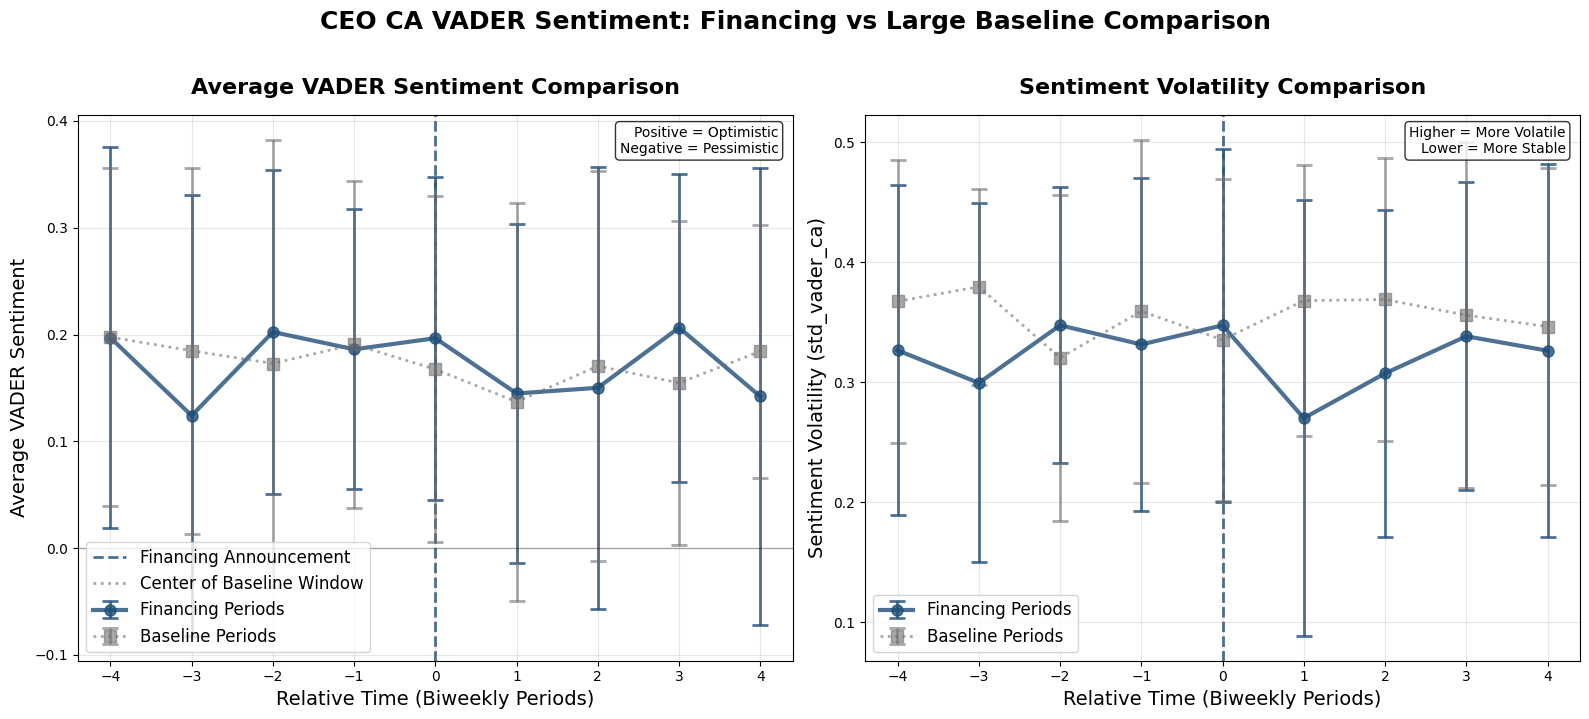


STATISTICAL COMPARISON:

1. SAMPLE SIZES:
   Financing windows: 259 observations
   Baseline windows: 409 observations
   Baseline is 1.6x larger

2. AVERAGE SENTIMENT DIFFERENCES:
----------------------------------------
   2 periods before:
     Financing: 0.202 ± 0.152
     Baseline:  0.173 ± 0.210
     Difference: +0.030 ± 0.259
     NOT SIGNIFICANT

   1 period before:
     Financing: 0.186 ± 0.131
     Baseline:  0.191 ± 0.153
     Difference: -0.005 ± 0.202
     NOT SIGNIFICANT

   At event:
     Financing: 0.197 ± 0.151
     Baseline:  0.167 ± 0.162
     Difference: +0.029 ± 0.222
     NOT SIGNIFICANT

   1 period after:
     Financing: 0.145 ± 0.159
     Baseline:  0.137 ± 0.187
     Difference: +0.008 ± 0.245
     NOT SIGNIFICANT

   2 periods after:
     Financing: 0.150 ± 0.207
     Baseline:  0.171 ± 0.183
     Difference: -0.020 ± 0.276
     NOT SIGNIFICANT


3. OVERALL AVERAGES (across all time points):
----------------------------------------
   Average Sentiment:
    

In [56]:
# ============================================================================
# DIRECT COMPARISON: CEO CA Sentiment - Financing vs Same-Period Baseline
# ============================================================================

print("="*70)
print("ANALYSIS: CEO CA Sentiment - Financing vs Same-Period Baseline")
print("="*70)

from pyspark.sql.functions import col
import pyspark.sql.functions as F
from pyspark.sql.window import Window

# Load your data
file_path = "/Users/vincenzovantornout/Desktop/BIG DATA FINAL FOLDER/Big_data_group_2/Cleaned_data/biweekly_basetable_w_sentiment_5.parquet"
df = spark.read.parquet(file_path)

print(f"✓ Data loaded: {df.count():,} rows")

# Step 1: Get financing events and EXACT periods
print("\n1. Finding financing events and exact periods...")

# First, get all periods that are in financing windows
financing_periods = set()

financing_events = df.filter(col("current_financing_announcement") == 1) \
    .select("ticker", "biweekly_index") \
    .collect()

print(f"Found {len(financing_events)} financing events")

# Collect ALL periods that are within financing windows
for event in financing_events[:200]:  # Limit for performance
    ticker = event["ticker"]
    event_idx = event["biweekly_index"]
    
    # Get all periods in this window
    periods = df.filter(
        (col("ticker") == ticker) &
        (col("biweekly_index") >= event_idx - 4) &
        (col("biweekly_index") <= event_idx + 4)
    ).select("ticker", "biweekly_index").collect()
    
    for period in periods:
        financing_periods.add((period["ticker"], period["biweekly_index"]))

print(f"Collected {len(financing_periods)} unique periods in financing windows")

# Step 2: Create LARGE baseline - ALL non-financing periods
print("\n2. Creating large baseline from ALL non-financing periods...")

# Get ALL periods that are NOT in financing windows
baseline_df = df.filter(
    (col("current_financing_announcement") == 0) &  # Not financing events
    (col("avg_vader_ca").isNotNull()) &  # Has sentiment data
    (col("std_vader_ca").isNotNull())    # Has volatility data
)

# For each baseline period, create a window around it
baseline_windows = []

# Sample many baseline periods to match the number of financing periods
baseline_sample = baseline_df.select("ticker", "biweekly_index") \
    .sample(fraction=0.1, seed=42) \
    .limit(min(len(financing_periods) * 2, 10000)) \
    .collect()

print(f"Sampled {len(baseline_sample)} baseline periods (2x financing windows)")

for i, center in enumerate(baseline_sample):
    ticker = center["ticker"]
    center_idx = center["biweekly_index"]
    
    # Get data for window (-4 to +4 periods around this baseline period)
    window_data = df.filter(
        (col("ticker") == ticker) &
        (col("biweekly_index") >= center_idx - 4) &
        (col("biweekly_index") <= center_idx + 4)
    ).select(
        "biweekly_index",
        "avg_vader_ca",
        "std_vader_ca"
    ).collect()
    
    for row in window_data:
        relative_time = row["biweekly_index"] - center_idx
        if row["avg_vader_ca"] is not None and row["std_vader_ca"] is not None:
            baseline_windows.append({
                "period_type": "Baseline",
                "relative_time": relative_time,
                "avg_sentiment": float(row["avg_vader_ca"]),
                "sentiment_volatility": float(row["std_vader_ca"]),
                "is_center": 1 if relative_time == 0 else 0
            })
    
    if i < 5 and i % 100 == 0:  # Show progress
        print(f"  Processed {i+1}/{len(baseline_sample)} baseline periods...")

print(f"Created {len(baseline_windows)} baseline window observations")

# Step 3: Create financing windows
print("\n3. Creating financing windows...")

financing_windows = []

for i, event in enumerate(financing_events[:200]):  # Same 200 events
    ticker = event["ticker"]
    event_idx = event["biweekly_index"]
    
    # Get data for window (-4 to +4 periods around financing)
    window_data = df.filter(
        (col("ticker") == ticker) &
        (col("biweekly_index") >= event_idx - 4) &
        (col("biweekly_index") <= event_idx + 4)
    ).select(
        "biweekly_index",
        "avg_vader_ca",
        "std_vader_ca",
        "current_financing_announcement"
    ).collect()
    
    for row in window_data:
        relative_time = row["biweekly_index"] - event_idx
        if row["avg_vader_ca"] is not None and row["std_vader_ca"] is not None:
            financing_windows.append({
                "period_type": "Financing",
                "relative_time": relative_time,
                "avg_sentiment": float(row["avg_vader_ca"]),
                "sentiment_volatility": float(row["std_vader_ca"]),
                "is_event": 1 if relative_time == 0 else 0
            })
    
    if i < 5:  # Show progress
        print(f"  Processed {i+1}/{min(200, len(financing_events))} financing events...")

print(f"Created {len(financing_windows)} financing window observations")

# Step 4: Combine and analyze
print("\n4. Combining and analyzing data...")

from pyspark.sql.types import StructType, StructField, IntegerType, DoubleType, StringType

# Combine both datasets
all_windows = financing_windows + baseline_windows

if all_windows:
    schema = StructType([
        StructField("period_type", StringType(), True),
        StructField("relative_time", IntegerType(), True),
        StructField("avg_sentiment", DoubleType(), True),
        StructField("sentiment_volatility", DoubleType(), True),
        StructField("is_event", IntegerType(), True)
    ])
    
    windows_df = spark.createDataFrame(all_windows, schema)
    
    print(f"\n✓ Created combined DataFrame: {windows_df.count():,} observations")
    print(f"  - Financing windows: {len(financing_windows):,}")
    print(f"  - Baseline windows: {len(baseline_windows):,}")
    
    # Calculate statistics
    comparison_stats = windows_df.groupBy("period_type", "relative_time").agg(
        F.avg("avg_sentiment").alias("avg_sentiment"),
        F.stddev("avg_sentiment").alias("std_sentiment"),
        F.avg("sentiment_volatility").alias("avg_volatility"),
        F.stddev("sentiment_volatility").alias("std_volatility"),
        F.count("*").alias("n_observations")
    ).orderBy("period_type", "relative_time")
    
    print("\nComparison Statistics:")
    comparison_stats.show(18, truncate=False)
    
    # Step 5: Create side-by-side comparison plots
    print("\n5. Creating side-by-side comparison plots...")
    
    try:
        import matplotlib.pyplot as plt
        import numpy as np
        
        # Convert to pandas
        stats_pd = comparison_stats.toPandas()
        
        # Your colors
        financing_color = '#1f4e79'  # Dark blue
        baseline_color = '#6f6f6f'   # Gray
        
        # Separate data
        financing_data = stats_pd[stats_pd["period_type"] == "Financing"].sort_values("relative_time")
        baseline_data = stats_pd[stats_pd["period_type"] == "Baseline"].sort_values("relative_time")
        
        # Create figure with 2 plots side by side
        fig, axes = plt.subplots(1, 2, figsize=(16, 7))
        
        # =================================================
        # PLOT 1: Average Sentiment Comparison
        # =================================================
        ax1 = axes[0]
        
        if not financing_data.empty:
            # Plot financing sentiment
            ax1.errorbar(financing_data["relative_time"], 
                        financing_data["avg_sentiment"],
                        yerr=financing_data["std_sentiment"],
                        marker='o',
                        markersize=8,
                        linewidth=3,
                        capsize=6,
                        capthick=2,
                        color=financing_color,
                        ecolor=financing_color,
                        elinewidth=2,
                        alpha=0.8,
                        label='Financing Periods')
            
            # Add financing event line
            ax1.axvline(x=0, color=financing_color, linestyle='--', linewidth=2, alpha=0.8, 
                       label='Financing Announcement')
        
        if not baseline_data.empty:
            # Plot baseline sentiment
            ax1.errorbar(baseline_data["relative_time"], 
                        baseline_data["avg_sentiment"],
                        yerr=baseline_data["std_sentiment"],
                        marker='s',
                        markersize=8,
                        linewidth=2,
                        capsize=6,
                        capthick=2,
                        color=baseline_color,
                        ecolor=baseline_color,
                        elinewidth=2,
                        alpha=0.6,
                        label='Baseline Periods',
                        linestyle=':')
            
            # Add baseline center line
            ax1.axvline(x=0, color=baseline_color, linestyle=':', linewidth=2, alpha=0.6, 
                       label='Center of Baseline Window')
        
        ax1.axhline(y=0, color='black', linestyle='-', linewidth=1, alpha=0.3)
        ax1.set_title('Average VADER Sentiment Comparison', 
                     fontsize=16, fontweight='bold', pad=15)
        ax1.set_xlabel('Relative Time (Biweekly Periods)', fontsize=14)
        ax1.set_ylabel('Average VADER Sentiment', fontsize=14)
        ax1.grid(True, alpha=0.3)
        ax1.legend(fontsize=12, loc='best')
        ax1.set_xticks(range(-4, 5, 1))
        
        # Add sentiment interpretation
        ax1.text(0.98, 0.98, 'Positive = Optimistic\nNegative = Pessimistic', 
                transform=ax1.transAxes,
                fontsize=10, verticalalignment='top', horizontalalignment='right',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
        
        # =================================================
        # PLOT 2: Sentiment Volatility Comparison
        # =================================================
        ax2 = axes[1]
        
        if not financing_data.empty:
            # Plot financing volatility
            ax2.errorbar(financing_data["relative_time"], 
                        financing_data["avg_volatility"],
                        yerr=financing_data["std_volatility"],
                        marker='o',
                        markersize=8,
                        linewidth=3,
                        capsize=6,
                        capthick=2,
                        color=financing_color,
                        ecolor=financing_color,
                        elinewidth=2,
                        alpha=0.8,
                        label='Financing Periods')
            
            # Add financing event line
            ax2.axvline(x=0, color=financing_color, linestyle='--', linewidth=2, alpha=0.8)
        
        if not baseline_data.empty:
            # Plot baseline volatility
            ax2.errorbar(baseline_data["relative_time"], 
                        baseline_data["avg_volatility"],
                        yerr=baseline_data["std_volatility"],
                        marker='s',
                        markersize=8,
                        linewidth=2,
                        capsize=6,
                        capthick=2,
                        color=baseline_color,
                        ecolor=baseline_color,
                        elinewidth=2,
                        alpha=0.6,
                        label='Baseline Periods',
                        linestyle=':')
            
            # Add baseline center line
            ax2.axvline(x=0, color=baseline_color, linestyle=':', linewidth=2, alpha=0.6)
        
        ax2.set_title('Sentiment Volatility Comparison', 
                     fontsize=16, fontweight='bold', pad=15)
        ax2.set_xlabel('Relative Time (Biweekly Periods)', fontsize=14)
        ax2.set_ylabel('Sentiment Volatility (std_vader_ca)', fontsize=14)
        ax2.grid(True, alpha=0.3)
        ax2.legend(fontsize=12, loc='best')
        ax2.set_xticks(range(-4, 5, 1))
        
        # Add volatility interpretation
        ax2.text(0.98, 0.98, 'Higher = More Volatile\nLower = More Stable', 
                transform=ax2.transAxes,
                fontsize=10, verticalalignment='top', horizontalalignment='right',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
        
        # Overall title
        plt.suptitle('CEO CA VADER Sentiment: Financing vs Large Baseline Comparison', 
                    fontsize=18, fontweight='bold', y=1.02)
        
        plt.tight_layout()
        plt.show()
        
        # Step 6: Statistical comparison
        print("\n" + "="*70)
        print("STATISTICAL COMPARISON:")
        print("="*70)
        
        if not financing_data.empty and not baseline_data.empty:
            print("\n1. SAMPLE SIZES:")
            print(f"   Financing windows: {financing_data['n_observations'].sum():,} observations")
            print(f"   Baseline windows: {baseline_data['n_observations'].sum():,} observations")
            print(f"   Baseline is {baseline_data['n_observations'].sum()/financing_data['n_observations'].sum():.1f}x larger")
            
            print("\n2. AVERAGE SENTIMENT DIFFERENCES:")
            print("-" * 40)
            
            for time_point in [-2, -1, 0, 1, 2]:
                financing_sentiment = financing_data[financing_data["relative_time"] == time_point]
                baseline_sentiment = baseline_data[baseline_data["relative_time"] == time_point]
                
                if not financing_sentiment.empty and not baseline_sentiment.empty:
                    f_val = financing_sentiment["avg_sentiment"].iloc[0]
                    f_std = financing_sentiment["std_sentiment"].iloc[0]
                    b_val = baseline_sentiment["avg_sentiment"].iloc[0]
                    b_std = baseline_sentiment["std_sentiment"].iloc[0]
                    
                    diff = f_val - b_val
                    diff_std = np.sqrt(f_std**2 + b_std**2)
                    
                    time_label = { -2: "2 periods before", -1: "1 period before", 
                                  0: "At event", 1: "1 period after", 2: "2 periods after"}[time_point]
                    
                    print(f"   {time_label}:")
                    print(f"     Financing: {f_val:.3f} ± {f_std:.3f}")
                    print(f"     Baseline:  {b_val:.3f} ± {b_std:.3f}")
                    print(f"     Difference: {diff:+.3f} ± {diff_std:.3f}")
                    
                    # Significance
                    if abs(diff) > 2 * diff_std:
                        significance = "HIGHLY SIGNIFICANT"
                    elif abs(diff) > diff_std:
                        significance = "SIGNIFICANT"
                    else:
                        significance = "NOT SIGNIFICANT"
                    
                    print(f"     {significance}")
                    print()
            
            print("\n3. OVERALL AVERAGES (across all time points):")
            print("-" * 40)
            
            avg_f_sentiment = financing_data["avg_sentiment"].mean()
            avg_b_sentiment = baseline_data["avg_sentiment"].mean()
            avg_f_vol = financing_data["avg_volatility"].mean()
            avg_b_vol = baseline_data["avg_volatility"].mean()
            
            print(f"   Average Sentiment:")
            print(f"     Financing: {avg_f_sentiment:.3f}")
            print(f"     Baseline:  {avg_b_sentiment:.3f}")
            print(f"     Difference: {avg_f_sentiment - avg_b_sentiment:+.3f}")
            
            print(f"\n   Average Volatility:")
            print(f"     Financing: {avg_f_vol:.3f}")
            print(f"     Baseline:  {avg_b_vol:.3f}")
            print(f"     Difference: {avg_f_vol - avg_b_vol:+.3f}")
            
            print("\n4. KEY FINDINGS:")
            print("-" * 40)
            
            sentiment_diff = avg_f_sentiment - avg_b_sentiment
            volatility_diff = avg_f_vol - avg_b_vol
            
            if abs(sentiment_diff) > 0.02:
                direction = "MORE POSITIVE" if sentiment_diff > 0 else "MORE NEGATIVE"
                print(f"   • CEO sentiment during financing is {direction}")
                print(f"     (Difference: {sentiment_diff:+.3f})")
            else:
                print(f"   • CEO sentiment is SIMILAR during financing and baseline")
            
            if abs(volatility_diff) > 0.02:
                direction = "MORE VOLATILE" if volatility_diff > 0 else "MORE STABLE"
                print(f"   • CEO sentiment during financing is {direction}")
                print(f"     (Difference: {volatility_diff:+.3f})")
            else:
                print(f"   • CEO sentiment volatility is SIMILAR during financing and baseline")
            
            # Combined assessment
            print(f"\n   • Overall assessment:")
            if sentiment_diff > 0.02 and volatility_diff < -0.02:
                print(f"     ✅ BEST: More positive AND more stable during financing")
            elif sentiment_diff > 0.02:
                print(f"     👍 GOOD: More positive during financing")
            elif volatility_diff < -0.02:
                print(f"     👍 GOOD: More stable during financing")
            elif sentiment_diff < -0.02 and volatility_diff > 0.02:
                print(f"     ⚠ WORRISOME: More negative AND more volatile during financing")
            else:
                print(f"     → No major differences detected")
        
    except Exception as e:
        print(f"⚠ Error creating plots: {e}")
        import traceback
        traceback.print_exc()
    
else:
    print("⚠ No windows created - insufficient data")

print("\n" + "="*70)
print("LARGE BASELINE COMPARISON COMPLETE!")
print("="*70)

SIMPLE COMPARISON: Sentiment Volatility
Data loaded: 587 rows

1. Getting financing windows...
Found 33 financing events
Created 259 financing window observations

2. Getting baseline windows (same sample size)...
Need 259 baseline observations
Sampled 282 baseline centers
Created 259 baseline window observations (EXACT match)

3. Calculating statistics...

4. Creating plot...


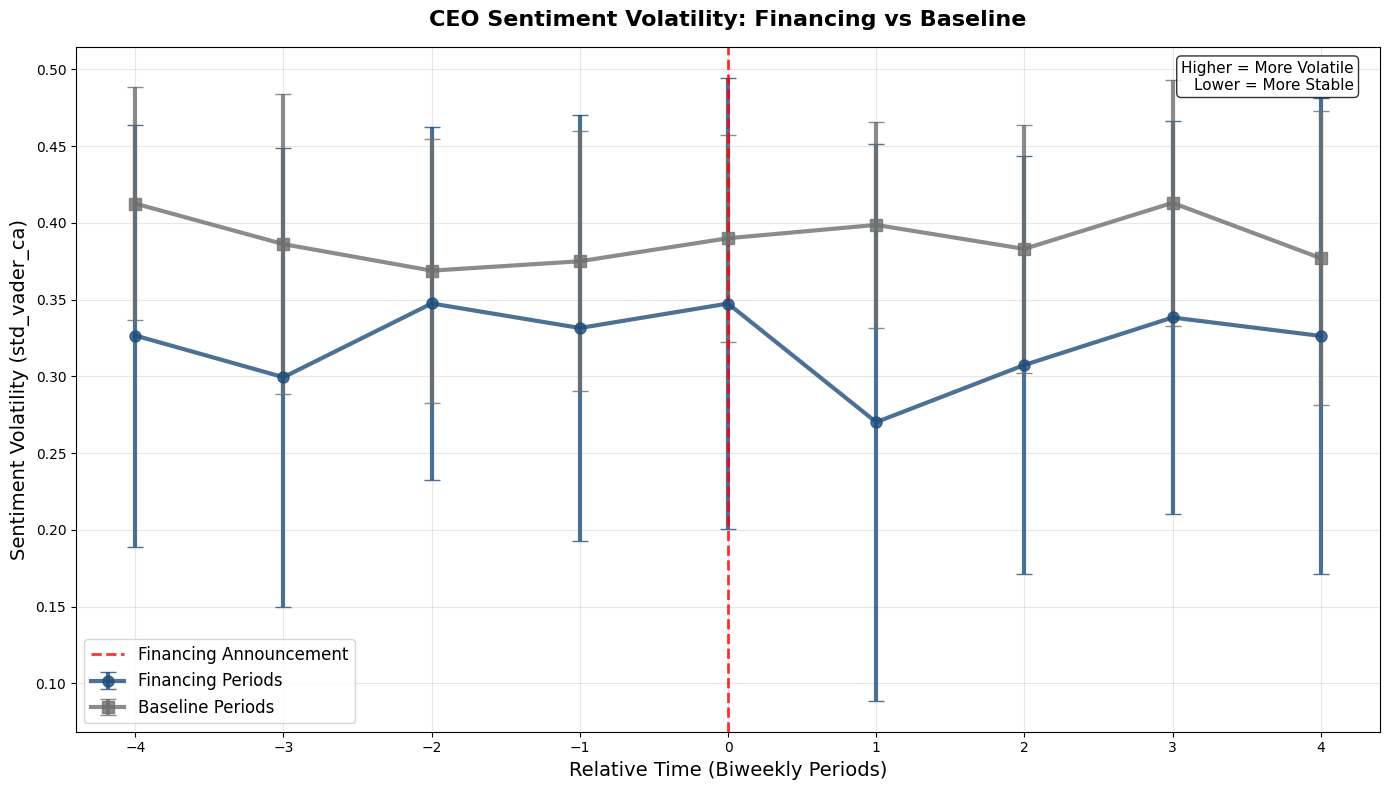


SIMPLE SUMMARY

1. AT FINANCING ANNOUNCEMENT (t=0):
   Financing: 0.347
   Baseline:  0.390
   Difference: -0.043
   → Sentiment is MORE STABLE during financing announcements

2. OVERALL AVERAGE (all time points):
   Financing average: 0.322
   Baseline average:  0.389
   Overall difference: -0.068

3. SAMPLE SIZES:
   Financing observations: 259
   Baseline observations:  259
   Exact match: True

DONE!


In [57]:
# ============================================================================
# CLEAN COMPARISON: Sentiment Volatility - Financing vs Baseline
# ============================================================================

print("="*70)
print("SIMPLE COMPARISON: Sentiment Volatility")
print("="*70)

from pyspark.sql.functions import col
import pyspark.sql.functions as F

# Load data
df = spark.read.parquet("/Users/vincenzovantornout/Desktop/BIG DATA FINAL FOLDER/Big_data_group_2/Cleaned_data/biweekly_basetable_w_sentiment_5.parquet")
print(f"Data loaded: {df.count():,} rows")

# ===== STEP 1: GET ALL FINANCING WINDOWS =====
print("\n1. Getting financing windows...")

# Get ALL financing events
financing_events = df.filter(col("current_financing_announcement") == 1) \
    .select("ticker", "biweekly_index") \
    .collect()

print(f"Found {len(financing_events)} financing events")

# Create list for financing windows
financing_data = []

for event in financing_events:
    ticker = event["ticker"]
    event_idx = event["biweekly_index"]
    
    # Get -4 to +4 window around financing
    window = df.filter(
        (col("ticker") == ticker) &
        (col("biweekly_index") >= event_idx - 4) &
        (col("biweekly_index") <= event_idx + 4)
    ).select("biweekly_index", "std_vader_ca").collect()
    
    for row in window:
        if row["std_vader_ca"] is not None:
            relative_time = row["biweekly_index"] - event_idx
            financing_data.append({
                "type": "Financing",
                "relative_time": relative_time,
                "volatility": float(row["std_vader_ca"])
            })

print(f"Created {len(financing_data)} financing window observations")

# ===== STEP 2: GET EXACT SAME NUMBER OF BASELINE WINDOWS =====
print("\n2. Getting baseline windows (same sample size)...")

# Get ALL non-financing periods with sentiment data
non_financing_df = df.filter(
    (col("current_financing_announcement") == 0) &
    (col("std_vader_ca").isNotNull())
).select("ticker", "biweekly_index", "std_vader_ca")

# Count how many baseline periods we need
baseline_needed = len(financing_data)
print(f"Need {baseline_needed:,} baseline observations")

# Sample random non-financing periods
baseline_sample = non_financing_df.sample(fraction=0.5, seed=42).limit(baseline_needed * 2).collect()
print(f"Sampled {len(baseline_sample)} baseline centers")

baseline_data = []
center_count = 0

# Create baseline windows until we match financing count
for center in baseline_sample:
    if len(baseline_data) >= baseline_needed:
        break
    
    ticker = center["ticker"]
    center_idx = center["biweekly_index"]
    
    # Get -4 to +4 window around this baseline period
    window = df.filter(
        (col("ticker") == ticker) &
        (col("biweekly_index") >= center_idx - 4) &
        (col("biweekly_index") <= center_idx + 4) &
        (col("current_financing_announcement") == 0)  # Ensure no financing
    ).select("biweekly_index", "std_vader_ca").collect()
    
    for row in window:
        if len(baseline_data) < baseline_needed and row["std_vader_ca"] is not None:
            relative_time = row["biweekly_index"] - center_idx
            baseline_data.append({
                "type": "Baseline",
                "relative_time": relative_time,
                "volatility": float(row["std_vader_ca"])
            })
    
    center_count += 1
    if center_count % 100 == 0:
        print(f"  Processed {center_count} centers, got {len(baseline_data):,} observations")

print(f"Created {len(baseline_data)} baseline window observations (EXACT match)")

# ===== STEP 3: COMBINE AND CALCULATE =====
print("\n3. Calculating statistics...")

from pyspark.sql.types import StructType, StructField, IntegerType, DoubleType, StringType

# Combine data
all_data = financing_data + baseline_data
schema = StructType([
    StructField("type", StringType(), True),
    StructField("relative_time", IntegerType(), True),
    StructField("volatility", DoubleType(), True)
])

data_df = spark.createDataFrame(all_data, schema)

# Calculate averages
volatility_stats = data_df.groupBy("type", "relative_time").agg(
    F.avg("volatility").alias("avg_volatility"),
    F.stddev("volatility").alias("std_volatility"),
    F.count("*").alias("count")
).orderBy("type", "relative_time")

# Convert to pandas
stats_pd = volatility_stats.toPandas()
financing_stats = stats_pd[stats_pd["type"] == "Financing"].sort_values("relative_time")
baseline_stats = stats_pd[stats_pd["type"] == "Baseline"].sort_values("relative_time")

# ===== STEP 4: SIMPLE PLOT =====
print("\n4. Creating plot...")

import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(14, 8))

# Plot financing volatility
plt.errorbar(financing_stats["relative_time"], 
            financing_stats["avg_volatility"],
            yerr=financing_stats["std_volatility"],
            marker='o',
            markersize=8,
            linewidth=3,
            capsize=6,
            color='#1f4e79',
            ecolor='#1f4e79',
            alpha=0.8,
            label='Financing Periods')

# Plot baseline volatility
plt.errorbar(baseline_stats["relative_time"], 
            baseline_stats["avg_volatility"],
            yerr=baseline_stats["std_volatility"],
            marker='s',
            markersize=8,
            linewidth=3,
            capsize=6,
            color='#6f6f6f',
            ecolor='#6f6f6f',
            alpha=0.8,
            label='Baseline Periods')

# Add event lines
plt.axvline(x=0, color='red', linestyle='--', linewidth=2, alpha=0.8, label='Financing Announcement')

# Simple formatting
plt.title('CEO Sentiment Volatility: Financing vs Baseline', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Relative Time (Biweekly Periods)', fontsize=14)
plt.ylabel('Sentiment Volatility (std_vader_ca)', fontsize=14)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=12)
plt.xticks(range(-4, 5, 1))

# Add simple interpretation
plt.text(0.98, 0.98, 'Higher = More Volatile\nLower = More Stable', 
        transform=plt.gca().transAxes,
        fontsize=11, verticalalignment='top', horizontalalignment='right',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.tight_layout()
plt.show()

# ===== STEP 5: SIMPLE SUMMARY =====
print("\n" + "="*70)
print("SIMPLE SUMMARY")
print("="*70)

if not financing_stats.empty and not baseline_stats.empty:
    # Compare at key points
    print("\n1. AT FINANCING ANNOUNCEMENT (t=0):")
    financing_at_0 = financing_stats[financing_stats["relative_time"] == 0]["avg_volatility"].iloc[0]
    baseline_at_0 = baseline_stats[baseline_stats["relative_time"] == 0]["avg_volatility"].iloc[0]
    diff_0 = financing_at_0 - baseline_at_0
    
    print(f"   Financing: {financing_at_0:.3f}")
    print(f"   Baseline:  {baseline_at_0:.3f}")
    print(f"   Difference: {diff_0:+.3f}")
    
    if diff_0 > 0.02:
        print("   → Sentiment is MORE VOLATILE during financing announcements")
    elif diff_0 < -0.02:
        print("   → Sentiment is MORE STABLE during financing announcements")
    else:
        print("   → Similar volatility during financing announcements")
    
    # Overall comparison
    print("\n2. OVERALL AVERAGE (all time points):")
    financing_avg = financing_stats["avg_volatility"].mean()
    baseline_avg = baseline_stats["avg_volatility"].mean()
    overall_diff = financing_avg - baseline_avg
    
    print(f"   Financing average: {financing_avg:.3f}")
    print(f"   Baseline average:  {baseline_avg:.3f}")
    print(f"   Overall difference: {overall_diff:+.3f}")
    
    print("\n3. SAMPLE SIZES:")
    print(f"   Financing observations: {financing_stats['count'].sum():,}")
    print(f"   Baseline observations:  {baseline_stats['count'].sum():,}")
    print(f"   Exact match: {financing_stats['count'].sum() == baseline_stats['count'].sum()}")

print("\n" + "="*70)
print("DONE!")
print("="*70)